# Interpretability concern

This notebook centralizes the analyses requested by reviewers:
- reported aggregate results from the manuscript tables
- optional node-level metrics (nMAPE, nRMSE) when raw predictions are exported
- optional temporal robustness on rolling windows
- optional attention-weight analysis for GAT-like models
- optional embedding analysis (PCA/UMAP)
- optional spatial error visualization
- optional computational cost comparison (if measured artifacts are exported)

By default, the notebook uses the true values reported in the paper tables.
Optional sections run only when detailed artifacts are available under `results_interpretability/`.

In [1]:
from pathlib import Path
import json
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
ARTIFACTS = ROOT / "results_interpretability"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Timing helpers used across sections
TIMINGS = {}
def tic(name: str):
    TIMINGS[name] = {"start": time.perf_counter()}
def toc(name: str):
    if name in TIMINGS and "start" in TIMINGS[name]:
        TIMINGS[name]["seconds"] = time.perf_counter() - TIMINGS[name]["start"]

# Enforce a single active dataset for the whole notebook run.
DATASET_CHOICES = ["rfrance", "weave"]
ACTIVE_DATASET = os.getenv("INTERPRET_DATASET", "rfrance").strip().lower()
if ACTIVE_DATASET not in DATASET_CHOICES:
    raise ValueError(f"Unknown INTERPRET_DATASET={ACTIVE_DATASET!r}. Expected one of {DATASET_CHOICES}.")
DATASET_CANDIDATES = [ACTIVE_DATASET]
EXPECTED_NODE_COUNT = {"rfrance": 12, "weave": 28}

print("Workspace root:", ROOT)
print("Artifacts dir:", ARTIFACTS)
print("Active dataset:", ACTIVE_DATASET)

Workspace root: /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf
Artifacts dir: /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_interpretability
Active dataset: rfrance


## 1) Load predictions and node metadata

Expected files:
- `results_interpretability/predictions.parquet` with columns:
  - `model`, `dataset`, `split`, `window_id`, `timestamp`, `node_id`, `y_true`, `y_pred`
- prediction exports saved as `.pt` files under `results_{dataset}/{model}/` or directly in `results_{dataset}/`
- this notebook enforces one active dataset per run (`rfrance` or `weave`)

- optional dataset-specific metadata file:
  - `results_interpretability/node_metadata_{dataset}.parquet`
- backward-compatible fallback:
  - `results_interpretability/node_metadata.parquet`

In [2]:
tic("load_predictions")

pred_path = ARTIFACTS / "predictions.parquet"
meta_path = ARTIFACTS / f"node_metadata_{ACTIVE_DATASET}.parquet"
legacy_meta_path = ARTIFACTS / "node_metadata.parquet"

# Explicitly skip FF folders/checkpoints during auto-discovery.
EXCLUDED_MODEL_PREFIXES = ["ff"]

PRED_KEYS = ["pred", "preds", "prediction", "predictions", "y_pred", "output", "outputs", "test_pred", "test_predictions", "uniform_pred", "bottom_up_pred", "top_down_pred"]
TARGET_KEYS = ["target", "targets", "y_true", "label", "labels", "test_target", "test_targets", "target_top"]


def _to_numpy_if_tensor(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    if isinstance(x, np.ndarray):
        return x
    return None


def _load_prediction_payload(path: Path):
    try:
        return torch.load(path, map_location="cpu")
    except Exception:
        try:
            return torch.load(path, map_location="cpu", weights_only=False)
        except Exception as e:
            return {"__load_error__": f"{type(e).__name__}: {str(e).splitlines()[0]}"}


def _find_first_array(obj, keys):
    if not isinstance(obj, dict):
        return None
    for key in keys:
        if key in obj:
            arr = _to_numpy_if_tensor(obj[key])
            if arr is not None:
                return arr
    for value in obj.values():
        if isinstance(value, dict):
            found = _find_first_array(value, keys)
            if found is not None:
                return found
    return None


def _prediction_array_to_frame(pred, model_name, dataset_name, target=None, split="test", source_name=None):
    pred = np.asarray(pred)
    target_arr = None if target is None else np.asarray(target)

    if pred.ndim == 0:
        pred = pred.reshape(1)
    if pred.ndim > 2:
        pred = pred.reshape(pred.shape[0], -1)
        if target_arr is not None:
            target_arr = np.asarray(target_arr)
            if target_arr.ndim == 0:
                target_arr = target_arr.reshape(1)
            if target_arr.ndim > 2:
                target_arr = target_arr.reshape(target_arr.shape[0], -1)

    def _frame_1d(values_pred, values_true, node_id):
        values_pred = np.asarray(values_pred).reshape(-1)
        if values_true is None:
            values_true = np.full(values_pred.shape[0], np.nan)
        else:
            values_true = np.asarray(values_true).reshape(-1)
            if values_true.shape[0] != values_pred.shape[0]:
                values_true = np.full(values_pred.shape[0], np.nan)
        window_id = np.arange(values_pred.shape[0])
        return pd.DataFrame({
            "model": model_name,
            "dataset": dataset_name,
            "split": split,
            "window_id": window_id,
            "timestamp": pd.to_datetime(window_id, unit="h", origin="2024-01-01"),
            "node_id": node_id,
            "y_true": values_true,
            "y_pred": values_pred,
            "source": source_name,
        })

    if pred.ndim == 1:
        true_1d = target_arr if (target_arr is not None and np.asarray(target_arr).ndim == 1) else None
        return _frame_1d(pred, true_1d, "aggregate")

    if pred.ndim == 2:
        n_rows, n_steps = pred.shape
        target_matrix = None
        if target_arr is not None:
            if target_arr.ndim == 2 and target_arr.shape == pred.shape:
                target_matrix = target_arr
            elif target_arr.ndim == 2 and target_arr.T.shape == pred.shape:
                target_matrix = target_arr.T
            elif target_arr.ndim == 1 and target_arr.shape[0] == n_steps:
                target_matrix = np.broadcast_to(target_arr, pred.shape)
            elif target_arr.ndim == 1 and target_arr.shape[0] == n_rows:
                target_matrix = np.broadcast_to(target_arr[:, None], pred.shape)
        frames = []
        for idx in range(n_rows):
            node_id = f"N{idx:03d}"
            true_row = None if target_matrix is None else target_matrix[idx]
            frames.append(_frame_1d(pred[idx], true_row, node_id))
        return pd.concat(frames, ignore_index=True)

    raise ValueError(f"Unsupported prediction shape: {pred.shape}")


def _payload_to_frames(payload, model_name, dataset_name, source_name):
    if isinstance(payload, torch.Tensor) or isinstance(payload, np.ndarray):
        return _prediction_array_to_frame(payload, model_name=model_name, dataset_name=dataset_name, source_name=source_name)

    if isinstance(payload, dict):
        if "__load_error__" in payload:
            return None

        ensemble_like = {"uniform_pred", "bottom_up_pred", "top_down_pred"} & set(payload.keys())
        if ensemble_like:
            target = payload.get("target_top")
            ensemble_rows = []
            for key, label in [("uniform_pred", "uniform"), ("bottom_up_pred", "bottom_up"), ("top_down_pred", "top_down")]:
                if key in payload:
                    ensemble_rows.append(
                        _prediction_array_to_frame(
                            payload[key],
                            model_name=label,
                            dataset_name=dataset_name,
                            target=target,
                            source_name=source_name,
                        )
                    )
            if ensemble_rows:
                return pd.concat(ensemble_rows, ignore_index=True)

        pred = _find_first_array(payload, PRED_KEYS)
        target = _find_first_array(payload, TARGET_KEYS)
        if pred is not None:
            return _prediction_array_to_frame(pred, model_name=model_name, dataset_name=dataset_name, target=target, source_name=source_name)

    return None


def _load_artifact_frame(path: Path, dataset_name: str):
    payload = _load_prediction_payload(path)
    if payload is None:
        return None

    source_name = path.stem
    model_name = path.parent.name if path.parent != ROOT else path.stem
    frame = _payload_to_frames(payload, model_name=model_name, dataset_name=dataset_name, source_name=source_name)

    if frame is None:
        return None

    if "model" not in frame.columns:
        frame["model"] = model_name
    if "dataset" not in frame.columns:
        frame["dataset"] = dataset_name
    if "split" not in frame.columns:
        frame["split"] = "test"
    if "source" not in frame.columns:
        frame["source"] = source_name
    return frame[[c for c in ["model", "dataset", "split", "window_id", "timestamp", "node_id", "y_true", "y_pred", "source"] if c in frame.columns]]


def _try_load_from_results_dirs():
    rows = []
    loaded_from = []

    direct_pt_paths = sorted(list(ROOT.glob("results_*/*.pt")) + list(ROOT.glob("results_*/*.pth")))
    for path in direct_pt_paths:
        dataset_name = path.parent.name.replace("results_", "")
        if dataset_name != ACTIVE_DATASET:
            continue
        frame = _load_artifact_frame(path, dataset_name=dataset_name)
        if frame is not None:
            rows.append(frame)
            loaded_from.append(str(path))

    for ds in DATASET_CANDIDATES:
        base = ROOT / f"results_{ds}"
        if not base.exists():
            continue

        for model_dir in [p for p in base.iterdir() if p.is_dir()]:
            model_name = model_dir.name
            if any(model_name.lower().startswith(pref) for pref in EXCLUDED_MODEL_PREFIXES):
                print(f"Skipping excluded model folder: {model_dir}")
                continue

            found_for_model = False
            for pt_path in sorted(list(model_dir.glob("*.pt")) + list(model_dir.glob("*.pth")) + list(model_dir.glob("**/*.pt")) + list(model_dir.glob("**/*.pth"))):
                frame = _load_artifact_frame(pt_path, dataset_name=ds)
                if frame is None:
                    continue
                rows.append(frame)
                loaded_from.append(str(pt_path))
                found_for_model = True
                break

            if found_for_model:
                continue

            for tab_name in ["predictions.parquet", "predictions.csv", "preds.parquet", "preds.csv"]:
                tab_path = model_dir / tab_name
                if not tab_path.exists():
                    continue

                df = pd.read_parquet(tab_path) if tab_path.suffix == ".parquet" else pd.read_csv(tab_path)
                if {"y_true", "y_pred"}.issubset(df.columns):
                    if "model" not in df.columns:
                        df["model"] = model_name
                    if "dataset" not in df.columns:
                        df["dataset"] = ds
                    if "split" not in df.columns:
                        df["split"] = "test"
                    if "window_id" not in df.columns:
                        df["window_id"] = np.arange(len(df))
                    if "timestamp" not in df.columns:
                        df["timestamp"] = pd.to_datetime(np.arange(len(df)), unit="h", origin="2024-01-01")
                    if "node_id" not in df.columns:
                        df["node_id"] = "aggregate"
                    rows.append(df[["model", "dataset", "split", "window_id", "timestamp", "node_id", "y_true", "y_pred"]])
                    loaded_from.append(str(tab_path))
                    break

    if len(rows):
        print("Loaded prediction artifacts from:")
        for p in loaded_from[:20]:
            print("-", p)
        if len(loaded_from) > 20:
            print(f"... and {len(loaded_from) - 20} more")
        return pd.concat(rows, ignore_index=True)
    return None

if pred_path.exists():
    df_pred = pd.read_parquet(pred_path)
    print("Loaded predictions from results_interpretability/predictions.parquet")
else:
    df_pred = _try_load_from_results_dirs()
    if df_pred is None:
        print("No prediction export found in results_{DATASET}/{model}.")
        print("Optional node-level and rolling-window analyses will be skipped until a .pt prediction export is loaded.")
    else:
        print("Loaded prediction export(s) from .pt and/or tabular artifacts.")
        if "y_true" in df_pred.columns and df_pred["y_true"].notna().any():
            print("At least one loaded artifact includes targets; node-level metrics can run for those rows.")
        else:
            print("Loaded prediction-only artifacts; node-level metrics will stay skipped until y_true is exported.")

if df_pred is not None and "dataset" in df_pred.columns:
    df_pred["dataset"] = df_pred["dataset"].astype(str).str.strip().str.lower()
    datasets_loaded = sorted([d for d in df_pred["dataset"].dropna().unique() if d])
    if len(datasets_loaded) > 1:
        raise ValueError(
            "Mixed datasets detected in loaded predictions: "
            f"{datasets_loaded}. Keep only one dataset per run (expected: {ACTIVE_DATASET})."
        )
    if len(datasets_loaded) == 1 and datasets_loaded[0] != ACTIVE_DATASET:
        raise ValueError(
            f"Loaded dataset '{datasets_loaded[0]}' does not match ACTIVE_DATASET='{ACTIVE_DATASET}'. "
            "Set INTERPRET_DATASET consistently or clean mixed artifacts."
        )

if meta_path.exists():
    df_meta = pd.read_parquet(meta_path)
    print(f"Loaded dataset-specific metadata: {meta_path.name}")
elif legacy_meta_path.exists():
    df_meta = pd.read_parquet(legacy_meta_path)
    print(f"Loaded legacy metadata file: {legacy_meta_path.name}")
else:
    df_meta = None
    print("No node metadata found: optional spatial maps will be skipped.")

if (df_pred is not None) and ("node_id" in df_pred.columns):
    node_count = int(df_pred["node_id"].nunique())
    expected_nodes = EXPECTED_NODE_COUNT.get(ACTIVE_DATASET)
    if expected_nodes is not None and node_count != expected_nodes:
        print(
            f"Warning: active dataset '{ACTIVE_DATASET}' expects {expected_nodes} unique nodes, "
            f"but predictions contain {node_count}."
        )

if (df_meta is not None) and ({"node_id"}.issubset(df_meta.columns)) and (df_pred is not None) and ({"node_id"}.issubset(df_pred.columns)):
    meta_nodes = set(df_meta["node_id"].astype(str))
    pred_nodes = set(df_pred["node_id"].astype(str))
    if len(meta_nodes.intersection(pred_nodes)) == 0:
        print(
            "Warning: metadata node ids do not overlap prediction node ids. "
            "Check whether metadata belongs to another dataset."
        )

toc("load_predictions")

if df_pred is not None:
    display(df_pred.head())
if df_meta is not None:
    display(df_meta.head())
print("Load timing (s):", round(TIMINGS.get("load_predictions", {}).get("seconds", np.nan), 3))

Skipping excluded model folder: /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/FF
Loaded prediction artifacts from:
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/GraphSAGE/GraphSAGE_1.pt
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/GATv2Conv/GATv2Conv_11.pt
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/TransformerConv/TransformerConv_12.pt
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/ChebConv/ChebConv_13.pt
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/TAGConv/TAGConv_14.pt
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/GATConv/GATConv_10.pt
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/GCNConv/GCNConv_0.pt
- /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_rfrance/APPNP/APPNP_15.pt
Loaded prediction export(s) from .pt and/or tabular artifacts.
Loaded prediction-only artifacts; node-level metrics will stay skipped until y_true is exported.
L

,model,dataset,split,window_id,timestamp,node_id,y_true,y_pred,source
0,GraphSAGE,rfrance,test,0,2024-01-01 00:00:00,N000,NaN,9062.824219,GraphSAGE_1
1,GraphSAGE,rfrance,test,1,2024-01-01 01:00:00,N000,NaN,8893.910156,GraphSAGE_1
2,GraphSAGE,rfrance,test,2,2024-01-01 02:00:00,N000,NaN,8684.345703,GraphSAGE_1
3,GraphSAGE,rfrance,test,3,2024-01-01 03:00:00,N000,NaN,8748.442383,GraphSAGE_1
4,GraphSAGE,rfrance,test,4,2024-01-01 04:00:00,N000,NaN,8617.062500,GraphSAGE_1


,node_id,lat,lon
0,N000,45.757814,4.832011
1,N001,47.321581,5.041470
2,N002,48.390528,-4.486009
3,N003,47.902734,1.908607
4,N004,48.584614,7.750713


Load timing (s): 0.69


In [3]:
# If node_metadata doesn't exist, create it from known geographic data (French dataset only).
if ACTIVE_DATASET != "rfrance":
    print(f"Skipping metadata auto-creation for dataset '{ACTIVE_DATASET}'.")
else:
    # Always define df_pos_rfrance so the region→node_id mapping is available throughout the notebook.
    df_pos_rfrance = pd.DataFrame({
        'region': ['Auvergne_Rhone_Alpes', 'Bourgogne_Franche_Comte', 'Bretagne', 'Centre_Val_de_Loire',
                    'Grand_Est', 'Hauts_de_France', 'Ile_de_France', 'Nouvelle_Aquitaine',
                    'Normandie', 'Occitanie', 'Pays_de_la_Loire', 'Provence_Alpes_Cote_d_Azur'],
        'lat': [45.7578137, 47.3215806, 48.3905283, 47.9027336,
                48.584614, 50.6365654, 48.862725, 44.841225,
                49.4404591, 43.6044622, 47.2186371, 43.2961743],
        'lon': [4.8320114, 5.0414701, -4.4860088, 1.9086066,
                7.7507127, 3.0635282, 2.287592, -0.5800364,
                1.0939658, 1.4442469, -1.5541362, 5.3699525],
    }).sort_values('region').reset_index(drop=True)
    df_pos_rfrance['node_id'] = [f"N{i:03d}" for i in range(len(df_pos_rfrance))]

    if not meta_path.exists():
        try:
            df_meta = df_pos_rfrance[['node_id', 'lat', 'lon']].copy()
            df_meta.to_parquet(meta_path, index=False)
            print(f"Created {meta_path.name} with {len(df_meta)} nodes.")
            print("Sample mapping:")
            print(df_meta.head())
        except Exception as e:
            print(f"Could not create node_metadata from geographic data: {e}")
    else:
        print(f"Dataset-specific metadata already exists: {meta_path.name}")


Dataset-specific metadata already exists: node_metadata_rfrance.parquet


## 3) Node-Level and Rolling-Window Diagnostics (optional)

This section computes node-level error summaries (nMAPE/nRMSE) and rolling-window stability when paired targets are available.

In [4]:
EPS = 1e-6

def compute_node_metrics(df: pd.DataFrame) -> pd.DataFrame:
    g = df.copy()
    g["ae"] = (g["y_true"] - g["y_pred"]).abs()
    g["se"] = (g["y_true"] - g["y_pred"])**2
    g["ape"] = g["ae"] / (g["y_true"].abs() + EPS)
    out = g.groupby(["dataset", "model", "node_id"], as_index=False).agg(
        nMAPE=("ape", "mean"),
        nRMSE=("se", lambda s: float(np.sqrt(np.mean(s)))),
        support=("timestamp", "count"),
    )
    return out


def window_metrics(df: pd.DataFrame) -> pd.DataFrame:
    g = df.copy()
    g["ae"] = (g["y_true"] - g["y_pred"]).abs()
    g["se"] = (g["y_true"] - g["y_pred"])**2
    g["ape"] = g["ae"] / (g["y_true"].abs() + EPS)
    wm = g.groupby(["dataset", "model", "window_id"], as_index=False).agg(
        MAPE=("ape", "mean"),
        RMSE=("se", lambda s: float(np.sqrt(np.mean(s)))),
    )
    return wm

if df_pred is None:
    df_scored = pd.DataFrame()
else:
    df_scored = df_pred[df_pred["y_true"].notna()].copy() if "y_true" in df_pred.columns else pd.DataFrame()

if df_scored.empty:
    df_node = pd.DataFrame()
    summary = pd.DataFrame()
    df_win = pd.DataFrame()
    robust = pd.DataFrame()
    if df_pred is None:
        print("Skipped: no prediction export available.")
    else:
        print("Skipped: loaded prediction exports do not include y_true values.")
    print("Note: node-level and rolling-window metrics require paired targets.")
else:
    df_node = compute_node_metrics(df_scored)
    summary = df_node.groupby(["dataset", "model"], as_index=False).agg(
        nMAPE_median=("nMAPE", "median"),
        nMAPE_q25=("nMAPE", lambda x: x.quantile(0.25)),
        nMAPE_q75=("nMAPE", lambda x: x.quantile(0.75)),
        nMAPE_p90=("nMAPE", lambda x: x.quantile(0.90)),
        nRMSE_median=("nRMSE", "median"),
        nRMSE_p90=("nRMSE", lambda x: x.quantile(0.90)),
    )
    df_win = window_metrics(df_scored)
    robust = df_win.groupby(["dataset", "model"], as_index=False).agg(
        MAPE_mean=("MAPE", "mean"),
        MAPE_std=("MAPE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
    )

    display(summary.sort_values(["dataset", "nMAPE_median"]))
    display(robust.sort_values(["dataset", "MAPE_mean"]))

Skipped: loaded prediction exports do not include y_true values.
Note: node-level and rolling-window metrics require paired targets.


In [5]:
if df_win.empty:
    print("Rolling-window plot skipped: no raw predictions export available.")
else:
    plt.figure(figsize=(10, 4))
    for model, d in df_win.groupby("model"):
        d = d.sort_values("window_id")
        plt.plot(d["window_id"], d["MAPE"], marker="o", alpha=0.7, label=model)

    plt.title("MAPE by rolling window")
    plt.xlabel("window_id")
    plt.ylabel("MAPE")
    plt.legend(ncol=3, fontsize=8)
    plt.tight_layout()
    plt.show()

Rolling-window plot skipped: no raw predictions export available.


## 4) Optional Training and Artifact Export

Run this only when attention/embedding artifacts are missing. Keep disabled for fast notebook execution.

In [39]:
# Optional timed training path to generate attention artifacts.
# Set to True only when you explicitly want to retrain.
TRAIN_GAT_FOR_ATTENTION = True
SELECTED_MODEL = "GATv2Conv"  # or "GATv2Conv"

if TRAIN_GAT_FOR_ATTENTION:
    tic("train_gat_attention")
    try:
        from torch_geometric import seed_everything
        from torch_geometric.nn.conv import GATConv, GATv2Conv
        from graphtoolbox.data.dataset import DataClass, GraphDataset
        from graphtoolbox.models.gnn import myGNN
        from graphtoolbox.training.trainer import Trainer

        DATASET = "rfrance"  # or "weave"
        OUT_CHANNELS = 48
        seed_everything(42)

        if DATASET == "weave":
            data_kwargs = {
                "node_var": "id_unique",
                "dummies": ["instant", "id_uniqueInt"],
                "day_inf_train": "2024-02-13",
                "day_sup_train": "2024-02-23",
                "day_inf_val": "2024-02-23",
                "day_sup_val": "2024-02-25",
                "day_inf_test": "2024-02-25",
                "day_sup_test": "2024-02-29",
            }
            dataset_kwargs = {
                "adj_matrix": "correlation",
                "features_base": ["instant", "id_uniqueInt", "weekday"],# + [f"consumption_l{t}" for t in range(1, 49)],
                "target_base": "consumption",
            }
            path_train = "./data/weave/train_weave.csv"
            path_test = "./data/weave/test_weave.csv"
            graph_folder = "./graph_representations_weave"
            cfg_path = Path("configs/config_weave.json")
        else:
            data_kwargs = {
                "node_var": "Region",
                "dummies": ["Instant", "JourSemaine", "DayType", "offset"],
                "day_inf_train": "2015-01-01",
                "day_sup_train": "2018-01-01",
                "day_inf_val": "2018-01-01",
                "day_sup_val": "2018-12-31",
                "day_inf_test": "2019-01-01",
                "day_sup_test": "2019-12-31",
            }
            dataset_kwargs = {
                'adj_matrix': 'gl3sr',
                'features_base': ['temp', 'nebu', 'wind', 'tempMax', 'tempMin', 'Posan', 'Instant', 'JourSemaine', 'JourFerie', 'offset', 'DayType', 'Weekend', 'temp_liss_fort', 'temp_liss_faible'] + [f'load_l{t}' for t in range(1, 48+1)],
                'feature_groups': {
                    'temp':     ['temp', 'tempMax', 'tempMin', 'temp_liss_fort'],
                    'calendar': ['Instant', 'JourSemaine', 'JourFerie'],
                    'lags':     [f'load_l{t}' for t in range(1, 49)],
                    'weather':  ['nebu', 'wind']
                },
                'target_base': 'load',
            }
            path_train = "./data/rfrance/train2.csv"
            path_test = "./data/rfrance/test2.csv"
            graph_folder = "./graph_representations_rfrance"
            cfg_path = Path("configs/config_rfrance.json")

        if not cfg_path.exists():
            raise FileNotFoundError(f"Missing config file: {cfg_path}")

        with open(cfg_path, "r") as f:
            cfg_all = json.load(f)
        cfg = cfg_all.get(SELECTED_MODEL, None)
        if cfg is None:
            raise KeyError(f"{SELECTED_MODEL} not found in config file")

        params = cfg["params"]
        dataset_kwargs["adj_matrix"] = 'dtw'

        data = DataClass(path_train=path_train, path_test=path_test, data_kwargs=data_kwargs, folder_config=".")
        ds_train = GraphDataset(data=data, period="train", graph_folder=graph_folder, dataset_kwargs=dataset_kwargs, out_channels=OUT_CHANNELS)
        ds_val = GraphDataset(data=data, period="val", scalers_feat=ds_train.scalers_feat, scalers_target=ds_train.scalers_target, graph_folder=graph_folder, dataset_kwargs=dataset_kwargs, out_channels=OUT_CHANNELS)
        ds_test = GraphDataset(data=data, period="test", scalers_feat=ds_train.scalers_feat, scalers_target=ds_train.scalers_target, graph_folder=graph_folder, dataset_kwargs=dataset_kwargs, out_channels=OUT_CHANNELS)

        model = myGNN(
            in_channels=ds_train.num_node_features,
            num_layers=params["num_layers"],
            hidden_channels=params["hidden_channels"],
            out_channels=OUT_CHANNELS,
            conv_class=GATv2Conv,
            conv_kwargs={"heads": params.get("heads", 1), "add_self_loops": False},
        )

        trainer = Trainer(
            model=model,
            dataset_train=ds_train,
            dataset_val=ds_val,
            dataset_test=ds_test,
            batch_size=params["batch_size"],
            return_attention=True,
            model_kwargs={"lr": params["lr"], "num_epochs": 300},
            lam_reg=0,
        )

        preds, targets, edge_index, attention_mats = trainer.train(plot_loss=False, force_training=True, save=True, patience=300)

        @torch.no_grad()
        def export_gat_embeddings(model, loader, node_names):
            device = next(model.parameters()).device
            model.eval()
            embedding_sum = None
            graph_count = 0

            for batch in loader:
                for attr in ["x", "y_scaled", "y", "edge_weight", "mask_y"]:
                    if getattr(batch, attr, None) is not None:
                        setattr(batch, attr, getattr(batch, attr).to(torch.float32))
                batch = batch.to(device)
                if hasattr(batch, "edge_weight") and batch.edge_weight is not None:
                    batch.edge_weight = batch.edge_weight.float()

                batch_vec = getattr(batch, "batch", None)
                if batch_vec is None:
                    batch_vec = torch.zeros(batch.x.shape[0], dtype=torch.long, device=device)

                num_graphs = int(batch_vec.max().item()) + 1
                num_nodes_per_graph = int((batch_vec == 0).sum().item())

                x = model.node_encoder(batch.x)
                x0 = x
                for layer in model.layers:
                    x = layer(
                        x,
                        batch.edge_index,
                        edge_weight=getattr(batch, "edge_weight", None),
                        x0=x0,
                        batch=batch_vec,
                    )

                z = model.layers[0].act(model.norm_final(x))
                z = z.view(num_graphs, num_nodes_per_graph, -1).detach().cpu()

                if embedding_sum is None:
                    embedding_sum = torch.zeros((num_nodes_per_graph, z.shape[-1]), dtype=z.dtype)

                embedding_sum += z.sum(dim=0)
                graph_count += num_graphs

            embedding_mean = embedding_sum / float(graph_count)
            rows = []
            emb_cols = [f"emb_{i}" for i in range(embedding_mean.shape[1])]
            for node_idx, node_name in enumerate(node_names):
                row = {"model": SELECTED_MODEL, "dataset": DATASET, "node_id": node_name}
                row.update({col: float(embedding_mean[node_idx, i]) for i, col in enumerate(emb_cols)})
                rows.append(row)
            return pd.DataFrame(rows)

        df_gat_emb = export_gat_embeddings(model, trainer.test_loader, ds_test.nodes)
        gat_emb_path = ARTIFACTS / "gat_embeddings.parquet"
        df_gat_emb.to_parquet(gat_emb_path, index=False)
        display(df_gat_emb.head())
        print(f"Saved {SELECTED_MODEL} embeddings to {gat_emb_path}")
        print(f"{SELECTED_MODEL} training finished and attention/embedding artifacts should be saved by Trainer.")
    except Exception as e:
        print("Optional GAT training path failed:", e)
    toc("train_gat_attention")
    print("GAT training+attention timing (s):", round(TIMINGS.get("train_gat_attention", {}).get("seconds", np.nan), 3))
else:
    print("TRAIN_GAT_FOR_ATTENTION=False -> skipping optional GAT training.")

Training model...


100%|██████████| 300/300 [04:47<00:00,  1.04it/s]


,model,dataset,node_id,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_349,emb_350,emb_351,emb_352,emb_353,emb_354,emb_355,emb_356,emb_357,emb_358
0,GATv2Conv,rfrance,Auvergne_Rhone_Alpes,0.000386,0.004780,0.022086,0.001426,0.450783,0.088779,0.007562,...,0.091734,0.084185,0.061247,0.007578,0.236255,0.041782,0.247168,0.004064,0.098259,0.087574
1,GATv2Conv,rfrance,Bourgogne_Franche_Comte,0.000344,0.005591,0.022277,0.000276,0.449886,0.087895,0.004845,...,0.089627,0.079133,0.060367,0.007186,0.234874,0.033843,0.202112,0.005439,0.102761,0.095434
2,GATv2Conv,rfrance,Bretagne,0.000427,0.004691,0.020645,0.002503,0.430871,0.083079,0.028001,...,0.089005,0.084253,0.059297,0.007641,0.224896,0.034188,0.246182,0.003330,0.089730,0.073436
3,GATv2Conv,rfrance,Centre_Val_de_Loire,0.000428,0.004593,0.020973,0.004282,0.442745,0.091572,0.013021,...,0.087355,0.091554,0.063890,0.005054,0.232780,0.033920,0.260875,0.003121,0.098205,0.084939
4,GATv2Conv,rfrance,Grand_Est,0.000296,0.006456,0.022299,0.000361,0.464533,0.095584,0.004695,...,0.098602,0.067396,0.057954,0.010484,0.235075,0.033098,0.171156,0.004335,0.112816,0.085674


Saved GATv2Conv embeddings to /Users/eloicampagne/Desktop/EDF/Weave/gnn4elf/results_interpretability/gat_embeddings.parquet
GATv2Conv training finished and attention/embedding artifacts should be saved by Trainer.
GAT training+attention timing (s): 301.419


## 5) Attention analysis (GAT / GATv2 / TransformerConv)

This section supports two workflows:
- exported edge-level table: `results_interpretability/attention_edges.parquet`
- legacy attention tensors saved by GraphToolbox under `attention_matrix/...`

Expected table file:
- `results_interpretability/attention_edges.parquet` with columns:
  - `model`, `dataset`, `timestamp`, `src`, `dst`, `attention`, optional `edge_prior`, optional `corr_abs`

No attention_edges.parquet found for Workflow A.
Loaded attention tensors: torch.Size([3, 2, 362, 144]) edge_index: torch.Size([2, 144])
Legacy attention load timing (s): 0.106
Global PCA scores shape: (362, 6)


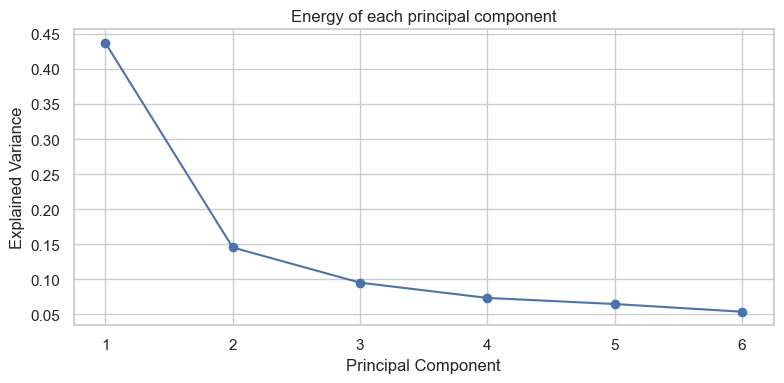

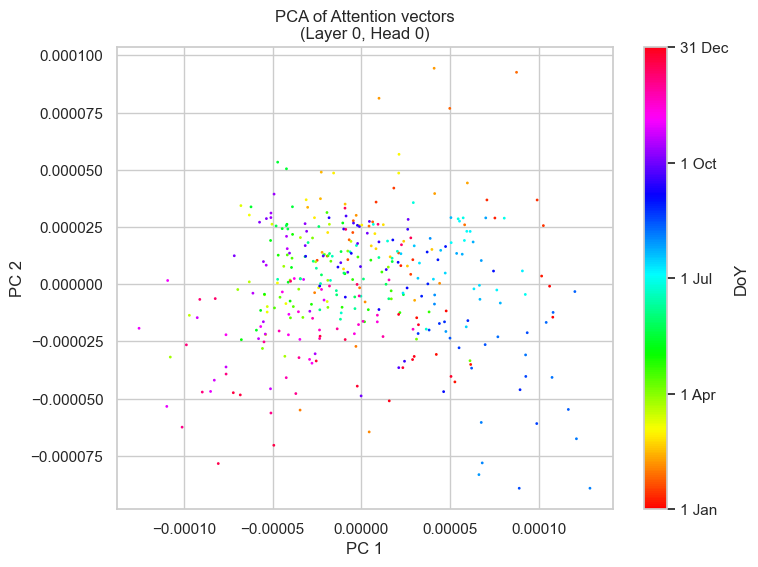

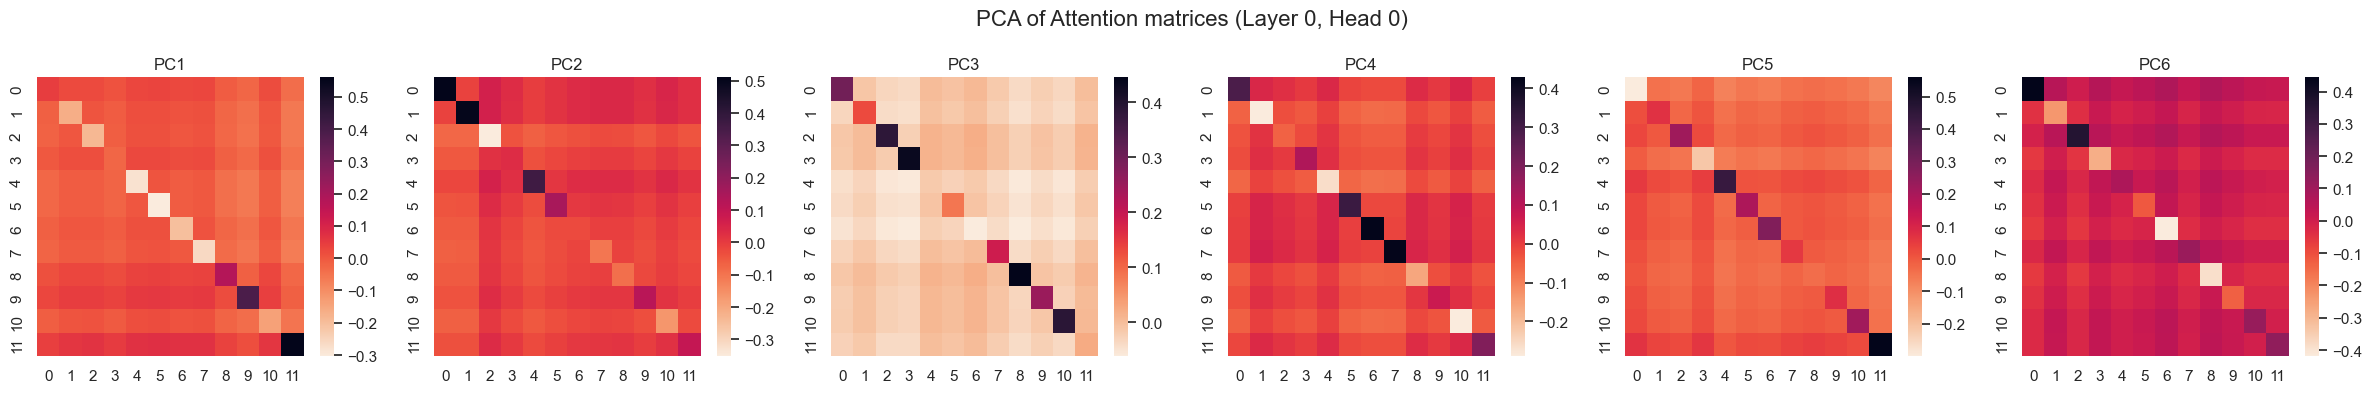

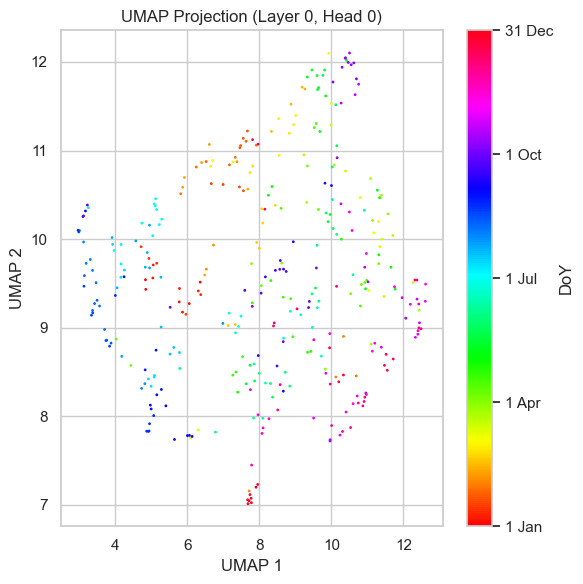

Attention section timing (s): 1.18


In [40]:
tic("attention_analysis")

# ---- Workflow A: edge-level parquet export ----
attn_path = ARTIFACTS / "attention_edges.parquet"
if attn_path.exists():
    df_attn = pd.read_parquet(attn_path)
    display(df_attn.head())

    top_edges = (
        df_attn.groupby(["dataset", "model", "src", "dst"], as_index=False)["attention"]
        .mean()
        .sort_values(["dataset", "model", "attention"], ascending=[True, True, False])
    )
    display(top_edges.groupby(["dataset", "model"]).head(10))

    if "timestamp" in df_attn.columns:
        edge_stability = df_attn.groupby(
            ["dataset", "model", "src", "dst"], as_index=False
        ).agg(
            attn_mean=("attention", "mean"),
            attn_std=("attention", "std"),
        )
        display(edge_stability.sort_values(["dataset", "model", "attn_mean"], ascending=[True, True, False]).head(20))

    if {"edge_prior", "corr_abs"}.issubset(df_attn.columns):
        align = df_attn.groupby(["dataset", "model"], as_index=False).apply(
            lambda x: pd.Series({
                "corr_attn_prior": x["attention"].corr(x["edge_prior"]),
                "corr_attn_corr": x["attention"].corr(x["corr_abs"]),
            })
        ).reset_index(drop=True)
        display(align)

    plt.figure(figsize=(7, 4))
    sns.histplot(df_attn["attention"], bins=50, kde=True)
    plt.title("Distribution of learned attention weights")
    plt.tight_layout()
    plt.show()
else:
    print("No attention_edges.parquet found for Workflow A.")

# ---- Workflow B: legacy GraphToolbox attention tensors ----
from pathlib import Path
import json

legacy_config_candidates = [
    Path("configs/config_rfrance.json"),
    Path("configs/config_weave.json"),
]
legacy_cfg_path = next((p for p in legacy_config_candidates if p.exists()), None)

if legacy_cfg_path is None:
    print("No config file found for Workflow B (expected configs/config_rfrance.json or configs/config_weave.json).")
else:
    try:
        from graphtoolbox.utils.attention import load_attention_batches, pca_global_mean, pca_analysis_attention, umap_analysis_attention

        with open(legacy_cfg_path, "r") as f:
            raw_cfg = json.load(f)

        attn_models = [k for k in raw_cfg.keys() if k in ["GATConv", "GATv2Conv", "TransformerConv"]]
        if len(attn_models) == 0:
            print(f"No attention-based model in {legacy_cfg_path}.")
        else:
            model_name = attn_models[0]
            params = raw_cfg[model_name]["params"]
            conv_name = raw_cfg[model_name].get("conv", model_name)
            if not isinstance(conv_name, str):
                conv_name = model_name
            adj_matrix = raw_cfg[model_name]["adj_matrix"]

            folder = Path("attention_matrix") / f"{conv_name}_{adj_matrix}" / (
                f"test_batch{params['batch_size']}_hidden{params['hidden_channels']}_"
                f"layers{params['num_layers']}_epochs30_heads{params.get('heads', 1)}"
            )

            if not folder.exists():
                print(f"Workflow B folder not found: {folder}")
                print("You can train a GAT with the paper config to generate this folder.")
            else:
                t_legacy = time.perf_counter()
                all_attn, edge_idx = load_attention_batches(str(folder))
                legacy_load_s = time.perf_counter() - t_legacy
                print("Loaded attention tensors:", all_attn.shape, "edge_index:", edge_idx.shape)
                print("Legacy attention load timing (s):", round(legacy_load_s, 3))

                num_nodes = int(edge_idx.max().item()) + 1
                glob = pca_global_mean(
                    all_attn, edge_idx, num_nodes=num_nodes, n_components=6
                )
                print("Global PCA scores shape:", np.asarray(glob["scores"]).shape)

                layer_idx, head_idx = 0, 0
                pca_analysis_attention(
                    all_attentions=all_attn,
                    edge_index=edge_idx,
                    layer_idx=layer_idx,
                    head_idx=head_idx,
                    n_components=6,
                )
                umap_analysis_attention(
                    all_attentions=all_attn,
                    edge_index=edge_idx,
                    layer_idx=layer_idx,
                    head_idx=head_idx,
                )
    except Exception as e:
        print("Workflow B failed (missing dependency or artifact):", e)

toc("attention_analysis")
print("Attention section timing (s):", round(TIMINGS.get("attention_analysis", {}).get("seconds", np.nan), 3))

## 7) Embedding Analysis (PCA / UMAP)

Expected file:
- `results_interpretability/gat_embeddings.parquet` with columns:
  - `model`, `dataset`, `node_id`, feature columns `emb_0`, `emb_1`, ...

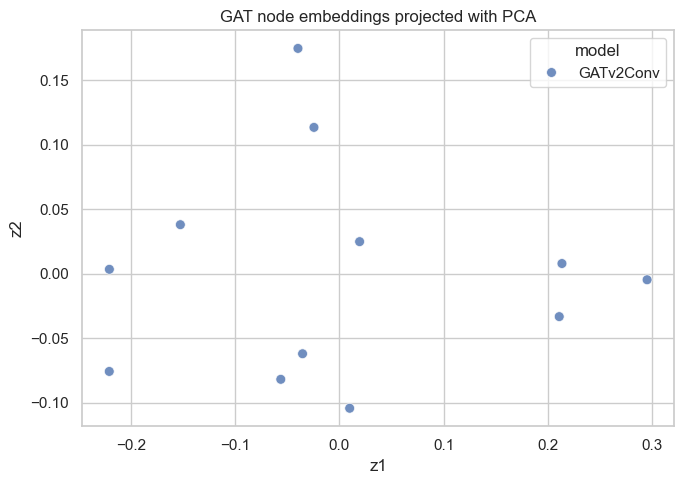

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


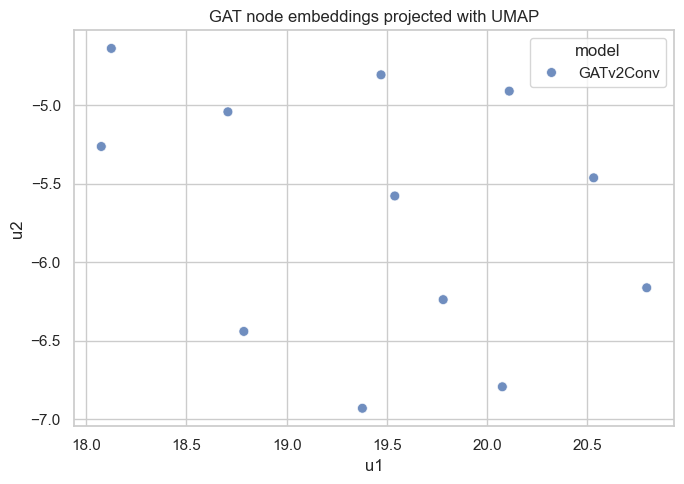

In [41]:
from sklearn.decomposition import PCA

emb_path = ARTIFACTS / "gat_embeddings.parquet"
if emb_path.exists():
    df_emb = pd.read_parquet(emb_path)
    emb_cols = [c for c in df_emb.columns if c.startswith("emb_")]
    if emb_cols:
        X = df_emb[emb_cols].to_numpy()
        pca = PCA(n_components=2, random_state=0)
        z = pca.fit_transform(X)
        df_plot = df_emb.copy()
        df_plot["z1"] = z[:, 0]
        df_plot["z2"] = z[:, 1]

        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=df_plot, x="z1", y="z2", hue="model", s=50, alpha=0.8)
        plt.title("GAT node embeddings projected with PCA")
        plt.tight_layout()
        plt.show()

        try:
            import umap
            reducer = umap.UMAP(n_components=2, random_state=0)
            u = reducer.fit_transform(X)
            df_plot["u1"] = u[:, 0]
            df_plot["u2"] = u[:, 1]

            plt.figure(figsize=(7, 5))
            sns.scatterplot(data=df_plot, x="u1", y="u2", hue="model", s=50, alpha=0.8)
            plt.title("GAT node embeddings projected with UMAP")
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print("UMAP not available or failed:", e)
    else:
        print("No embedding columns detected (expected emb_*)")
else:
    print("No GAT embedding file found. Run the optional GAT export cell to create gat_embeddings.parquet.")

## 6) GAT Node Error Extraction (required by downstream interpretability)

Compute node-level GAT nMAPE/nRMSE by combining GAT predictions with reference targets on aligned timestamps and node ids.

In [42]:
# Extract GAT errors: use GATConv predictions with best available targets
if df_pred is not None:
    print("Computing GAT node-level errors from GATConv predictions...")
    tic("gat_error_extraction")

    try:
        gat_preds = df_pred[df_pred["model"] == "GATConv"].copy()
        if gat_preds.empty:
            raise ValueError("No GATConv predictions in df_pred")

        def _targets_from_dataset(dataset_obj, prefer_scaled):
            target_order = ["Y_scaled", "Y_node", "y_scaled", "y_node", "Y", "y"] if prefer_scaled else ["Y_node", "Y_scaled", "y_node", "y_scaled", "Y", "y"]
            for attr_name in target_order:
                if not hasattr(dataset_obj, attr_name):
                    continue
                candidate_value = getattr(dataset_obj, attr_name)
                if candidate_value is None:
                    continue
                if hasattr(candidate_value, "detach"):
                    candidate_value = candidate_value.detach().cpu().numpy()
                else:
                    candidate_value = np.asarray(candidate_value)
                return attr_name, candidate_value
            return None, None

        def _looks_scaled(values):
            finite_values = np.asarray(values, dtype=float)
            finite_values = finite_values[np.isfinite(finite_values)]
            if finite_values.size == 0:
                return False
            return float(np.nanmin(finite_values)) >= -0.5 and float(np.nanmax(finite_values)) <= 2.0

        pred_node_ids = None
        if "node_id" in gat_preds.columns:
            pred_node_ids = list(pd.Index(gat_preds["node_id"]).drop_duplicates())
        pred_timestamps = None
        if "timestamp" in gat_preds.columns:
            pred_timestamps = list(pd.Index(gat_preds["timestamp"]).drop_duplicates())

        def _reference_frame_from_array(target_array, source_name):
            node_names = pred_node_ids
            if node_names is None:
                for attr_name in ["nodes", "node_names", "node_ids"]:
                    if hasattr(ds_test, attr_name):
                        node_names = list(getattr(ds_test, attr_name))
                        break
            if node_names is None:
                if target_array.ndim == 2:
                    node_names = [f"N{i:03d}" for i in range(target_array.shape[0])]
                else:
                    node_names = ["aggregate"]

            timestamps = pred_timestamps
            if timestamps is None:
                timestamps = None

            if target_array.ndim == 2:
                frames = []
                for node_idx, node_name in enumerate(node_names[: target_array.shape[0]]):
                    if timestamps is not None and len(timestamps) == target_array.shape[1]:
                        ts_values = timestamps
                    else:
                        ts_values = pd.to_datetime(np.arange(target_array.shape[1]), unit="h", origin="2024-01-01")
                    frames.append(pd.DataFrame({
                        "node_id": node_name,
                        "timestamp": ts_values,
                        "y_true": target_array[node_idx],
                        "source": source_name,
                    }))
                return pd.concat(frames, ignore_index=True)

            if target_array.ndim == 1:
                if timestamps is not None and len(timestamps) == target_array.shape[0]:
                    ts_values = timestamps
                else:
                    ts_values = pd.to_datetime(np.arange(target_array.shape[0]), unit="h", origin="2024-01-01")
                return pd.DataFrame({
                    "node_id": ["aggregate"] * target_array.shape[0],
                    "timestamp": ts_values,
                    "y_true": target_array,
                    "source": source_name,
                })

            return None

        ref_targets = None
        prefer_scaled_targets = _looks_scaled(gat_preds["y_pred"].to_numpy(dtype=float))
        dataset_source, dataset_targets = _targets_from_dataset(ds_test, prefer_scaled=prefer_scaled_targets)
        if dataset_targets is not None:
            ref_targets = _reference_frame_from_array(dataset_targets, dataset_source)

        if ref_targets is None or ref_targets.empty:
            def _load_reference_targets_from_artifacts():
                reference_candidates = []
                target_paths = [
                    ROOT / f"results_{ACTIVE_DATASET}" / "ADLGNN" / "adlgnn_nodeT_preds.pt",
                    ROOT / f"results_{ACTIVE_DATASET}" / "ADLGNN" / "adlgnn_hpo_nodeT_preds.pt",
                    ROOT / f"results_{ACTIVE_DATASET}" / "graph_models_ensemble_predictions.pt",
                    ROOT / f"results_{ACTIVE_DATASET}" / "graph_models_ensemble_predictions_runs.pt",
                ]

                for target_path in target_paths:
                    if not target_path.exists():
                        continue
                    payload = _load_prediction_payload(target_path)
                    if not isinstance(payload, dict):
                        continue
                    if {"y_true", "y_pred"}.issubset(payload.keys()):
                        arr_true = np.asarray(payload["y_true"])
                        candidate_frame = _reference_frame_from_array(arr_true, target_path.stem)
                        if candidate_frame is not None:
                            reference_candidates.append(candidate_frame)
                            continue
                    if "target_top" in payload:
                        arr_true = np.asarray(payload["target_top"])
                        candidate_frame = _reference_frame_from_array(arr_true, target_path.stem)
                        if candidate_frame is not None:
                            reference_candidates.append(candidate_frame)

                if reference_candidates:
                    return pd.concat(reference_candidates, ignore_index=True)
                return None

            ref_targets = _load_reference_targets_from_artifacts()

        if ref_targets is None or ref_targets.empty:
            print("No y_true values found in ds_test or reference artifacts; skipping GAT error extraction.")
            df_gat_errors = None
        else:
            if "model" in ref_targets.columns:
                non_gat_ref = ref_targets[ref_targets["model"] != "GATConv"].copy()
                if not non_gat_ref.empty:
                    ref_targets = non_gat_ref

            if "timestamp" not in ref_targets.columns:
                print("No timestamp column available for GAT error alignment; skipping GAT error extraction.")
                df_gat_errors = None
            else:
                if "node_id" not in ref_targets.columns:
                    ref_targets = ref_targets.copy()
                    ref_targets["node_id"] = "aggregate"
                ref_targets = ref_targets[["node_id", "timestamp", "y_true"]].drop_duplicates()
                gat_with_targets = gat_preds[["node_id", "timestamp", "y_pred"]].merge(
                    ref_targets, on=["node_id", "timestamp"], how="inner"
                )
                if gat_with_targets.empty:
                    print("No matching targets found for GATConv predictions; skipping GAT error extraction.")
                    df_gat_errors = None
                else:

                    gat_with_targets["ae"] = (gat_with_targets["y_true"] - gat_with_targets["y_pred"]).abs()
                    gat_with_targets["se"] = (gat_with_targets["y_true"] - gat_with_targets["y_pred"]) ** 2
                    gat_with_targets["ape"] = gat_with_targets["ae"] / (gat_with_targets["y_true"].abs() + EPS)

                    gat_node_errors = gat_with_targets.groupby("node_id", as_index=False).agg(
                        nMAPE=("ape", "mean"),
                        nRMSE=("se", lambda s: float(np.sqrt(np.mean(s)))),
                        support=("timestamp", "count"),
                    )
                    gat_node_errors["model"] = "GAT"
                    df_gat_errors = gat_node_errors[["node_id", "nMAPE", "nRMSE", "model"]].copy()

                    print(f"✓ Computed GAT errors for {len(df_gat_errors)} nodes using reference targets")
                    display(df_gat_errors)

                    toc("gat_error_extraction")
                    print(f"GAT error extraction timing (s): {TIMINGS.get('gat_error_extraction', {}).get('seconds', np.nan):.3f}")

    except Exception as e:
        print(f"Failed to compute GAT errors: {type(e).__name__}: {str(e)[:200]}")
        df_gat_errors = None
else:
    print("No predictions available - GAT error extraction skipped")
    df_gat_errors = None

Computing GAT node-level errors from GATConv predictions...
✓ Computed GAT errors for 12 nodes using reference targets


,node_id,nMAPE,nRMSE,model
0,N000,0.020507,206.410446,GAT
1,N001,0.025424,82.031227,GAT
2,N002,0.020949,78.358086,GAT
3,N003,0.035509,107.787743,GAT
4,N004,0.021539,159.892639,GAT
5,N005,0.019827,155.334595,GAT
6,N006,0.026216,270.721313,GAT
7,N007,0.022217,93.560478,GAT
8,N008,0.023904,157.142166,GAT
9,N009,0.023194,137.210052,GAT


GAT error extraction timing (s): 0.232


## 8) Integrated Embedding-Position Map + Important Connections

Combines node embeddings, node errors, and top adjacency/attention connections in a compact reviewer-facing view.


EMBEDDING-POSITION CORRELATION MAP

Correlation between geographic and embedding distances:
  Geographic distances: min=1.032092, max=12.238261
  Embedding distances: min=0.137492, max=0.524285
  Correlation r: 0.440303


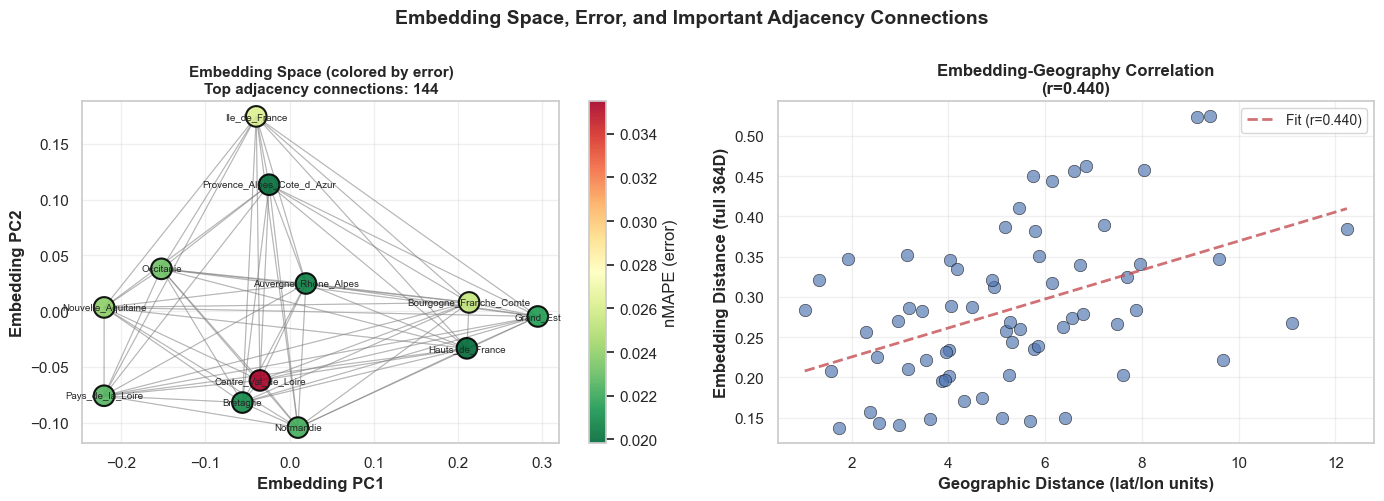


✓ Updated embedding-position map complete

Timing (s): nan


In [43]:
toc("integrated_spatial_map")

has_embeddings = ('df_gat_emb' in globals()) and (df_gat_emb is not None) and (not df_gat_emb.empty) and any(c.startswith("emb_") for c in df_gat_emb.columns)
has_errors = ('df_gat_errors' in globals()) and (df_gat_errors is not None) and (not df_gat_errors.empty)

# Embedding-position correlation visualization (embedding view + distance correlation)
if has_embeddings and has_errors and df_meta is not None:
    print("\n" + "=" * 60)
    print("EMBEDDING-POSITION CORRELATION MAP")
    print("=" * 60)

    try:
        from scipy.spatial.distance import pdist, squareform

        if df_gat_emb is not None and not df_gat_emb.empty:
            emb_cols_full = [c for c in df_gat_emb.columns if c.startswith("emb_")]
            if emb_cols_full:
                emb_data = df_gat_emb[emb_cols_full].fillna(0).values
                node_ids_emb = df_gat_emb["node_id"].values

                # Build mappings between embedding node ids and Nxxx ids when possible
                emb_to_nid = {}
                if len(node_ids_emb) and str(node_ids_emb[0]).startswith("N"):
                    emb_to_nid = {nid: nid for nid in node_ids_emb}
                elif "df_pos_rfrance" in globals() and {"region", "node_id"}.issubset(set(df_pos_rfrance.columns)):
                    emb_to_nid = dict(zip(df_pos_rfrance["region"], df_pos_rfrance["node_id"]))
                n_to_emb = {v: k for k, v in emb_to_nid.items()}
                emb_index = {nid: i for i, nid in enumerate(node_ids_emb)}

                # Build node errors aligned with embedding nodes
                emb_errors = np.full(len(node_ids_emb), np.nan, dtype=float)
                if df_gat_errors is not None and not df_gat_errors.empty:
                    err_map = dict(zip(df_gat_errors["node_id"], df_gat_errors["nMAPE"]))
                    for i, nid in enumerate(node_ids_emb):
                        if nid in err_map:
                            emb_errors[i] = float(err_map[nid])
                        else:
                            mapped_nid = emb_to_nid.get(nid)
                            if mapped_nid in err_map:
                                emb_errors[i] = float(err_map[mapped_nid])

                if np.isnan(emb_errors).all():
                    emb_errors = np.zeros(len(node_ids_emb), dtype=float)
                else:
                    fill_val = np.nanmean(emb_errors)
                    emb_errors = np.where(np.isnan(emb_errors), fill_val, emb_errors)

                # Geographic coordinates aligned to embedding-node order
                meta_latlon = {}
                if {"node_id", "lat", "lon"}.issubset(set(df_meta.columns)):
                    meta_latlon = {
                        r["node_id"]: (float(r["lat"]), float(r["lon"]))
                        for _, r in df_meta.iterrows()
                    }

                geo_coords = []
                valid_node_idx = []
                for i, nid in enumerate(node_ids_emb):
                    if nid in meta_latlon:
                        geo_coords.append(meta_latlon[nid])
                        valid_node_idx.append(i)
                    else:
                        mapped_nid = emb_to_nid.get(nid)
                        if mapped_nid in meta_latlon:
                            geo_coords.append(meta_latlon[mapped_nid])
                            valid_node_idx.append(i)
                        elif "df_pos_rfrance" in globals() and {"region", "lat", "lon"}.issubset(set(df_pos_rfrance.columns)):
                            rr = df_pos_rfrance[df_pos_rfrance["region"] == nid]
                            if not rr.empty:
                                geo_coords.append((float(rr.iloc[0]["lat"]), float(rr.iloc[0]["lon"])))
                                valid_node_idx.append(i)

                if len(valid_node_idx) < 2:
                    raise ValueError("Not enough nodes with aligned geographic coordinates")

                emb_data_valid = emb_data[valid_node_idx]
                emb_dist_full = squareform(pdist(emb_data_valid, metric="euclidean"))
                geo_coords_arr = np.array(geo_coords, dtype=float)
                geo_dist = squareform(pdist(geo_coords_arr, metric="euclidean"))

                # Extract upper triangle (unique pairs)
                n = len(valid_node_idx)
                geo_upper = geo_dist[np.triu_indices(n, k=1)]
                emb_upper = emb_dist_full[np.triu_indices(n, k=1)]

                # Create 2-panel visualization: embedding + correlation
                fig, axes = plt.subplots(1, 2, figsize=(14, 5))

                # Panel 1: Embedding space (PCA) + most important adjacency connections
                pca_2d = PCA(n_components=2, random_state=42)
                emb_2d = pca_2d.fit_transform(emb_data)

                ax_emb = axes[0]
                scatter_emb = ax_emb.scatter(
                    emb_2d[:, 0],
                    emb_2d[:, 1],
                    c=emb_errors,
                    s=220,
                    cmap=plt.cm.RdYlGn_r,
                    edgecolors="black",
                    linewidth=1.5,
                    alpha=0.9,
                    zorder=3,
                )
                plt.colorbar(scatter_emb, ax=ax_emb, label="nMAPE (error)")

                # Draw top adjacency connections if edge_index exists
                n_edges_drawn = 0
                edge_attn = globals().get("edge_attn", {})
                if "edge_idx" in globals() and edge_idx is not None:
                    edge_scores = []
                    for src, dst in zip(edge_idx[0], edge_idx[1]):
                        src_id = int(src.item())
                        dst_id = int(dst.item())

                        # Importance: attention mean when available, fallback to 1.0
                        score = 1.0
                        if isinstance(edge_attn, dict) and len(edge_attn) > 0:
                            if (src_id, dst_id) in edge_attn:
                                score = float(edge_attn[(src_id, dst_id)].get("mean", 1.0))
                            elif (dst_id, src_id) in edge_attn:
                                score = float(edge_attn[(dst_id, src_id)].get("mean", 1.0))
                        edge_scores.append((src_id, dst_id, score))

                    if len(edge_scores) > 0:
                        scores = np.array([s for _, _, s in edge_scores], dtype=float)
                        thr = np.percentile(scores, 70)
                        top_edges = [(u, v, s) for (u, v, s) in edge_scores if s >= thr]

                        if len(top_edges) > 0:
                            smin = min(s for _, _, s in top_edges)
                            smax = max(s for _, _, s in top_edges)
                            denom = (smax - smin) if (smax - smin) > 1e-12 else 1.0

                            for u, v, s in top_edges:
                                nu = f"N{u:03d}"
                                nv = f"N{v:03d}"
                                emb_u = n_to_emb.get(nu, nu)
                                emb_v = n_to_emb.get(nv, nv)

                                if emb_u in emb_index and emb_v in emb_index:
                                    iu = emb_index[emb_u]
                                    iv = emb_index[emb_v]
                                    lw = 0.8 + 2.2 * ((s - smin) / denom)
                                    ax_emb.plot(
                                        [emb_2d[iu, 0], emb_2d[iv, 0]],
                                        [emb_2d[iu, 1], emb_2d[iv, 1]],
                                        color="gray",
                                        alpha=0.35,
                                        linewidth=lw,
                                        zorder=1,
                                    )
                                    n_edges_drawn += 1

                for i, nid in enumerate(node_ids_emb):
                    ax_emb.annotate(nid, (emb_2d[i, 0], emb_2d[i, 1]), fontsize=7, ha="center", va="center")

                ax_emb.set_xlabel("Embedding PC1", fontweight="bold")
                ax_emb.set_ylabel("Embedding PC2", fontweight="bold")
                ax_emb.set_title(
                    f"Embedding Space (colored by error)\nTop adjacency connections: {n_edges_drawn}",
                    fontweight="bold",
                    fontsize=11,
                )
                ax_emb.grid(alpha=0.3)

                # Panel 2: Correlation between geographic and embedding distances
                ax_corr = axes[1]
                ax_corr.scatter(geo_upper, emb_upper, s=80, alpha=0.65, edgecolors="black", linewidth=0.5)

                valid_mask = ~(np.isnan(geo_upper) | np.isnan(emb_upper))
                corr_geo_emb = np.nan
                if np.sum(valid_mask) > 2:
                    valid_geo = geo_upper[valid_mask]
                    valid_emb = emb_upper[valid_mask]

                    corr_geo_emb = np.corrcoef(valid_geo, valid_emb)[0, 1]
                    print("\nCorrelation between geographic and embedding distances:")
                    print(f"  Geographic distances: min={geo_upper.min():.6f}, max={geo_upper.max():.6f}")
                    print(f"  Embedding distances: min={emb_upper.min():.6f}, max={emb_upper.max():.6f}")
                    print(f"  Correlation r: {corr_geo_emb:.6f}")

                    if not np.isnan(corr_geo_emb):
                        z = np.polyfit(valid_geo, valid_emb, 1)
                        p = np.poly1d(z)
                        ax_corr.plot(
                            sorted(valid_geo),
                            p(sorted(valid_geo)),
                            "r--",
                            alpha=0.8,
                            linewidth=2,
                            label=f"Fit (r={corr_geo_emb:.3f})",
                        )
                        ax_corr.legend(fontsize=10)

                ax_corr.set_xlabel("Geographic Distance (lat/lon units)", fontweight="bold")
                ax_corr.set_ylabel("Embedding Distance (full 364D)", fontweight="bold")
                ax_corr.set_title(f"Embedding-Geography Correlation\n(r={corr_geo_emb:.3f})", fontweight="bold", fontsize=12)
                ax_corr.grid(alpha=0.3)

                plt.suptitle("Embedding Space, Error, and Important Adjacency Connections", fontsize=14, fontweight="bold", y=1.00)
                plt.tight_layout()
                plt.show()

                print("\n✓ Updated embedding-position map complete")

    except Exception as e:
        import traceback
        print(f"Failed: {type(e).__name__}: {str(e)}")
        traceback.print_exc()

toc("integrated_spatial_map")
print(f"\nTiming (s): {TIMINGS.get('integrated_spatial_map', {}).get('seconds', np.nan):.3f}")

## 9) Rigorous GAT Interpretability Experiments

Reviewer-oriented protocol to test what GAT attention actually learns:
1. Attention diagnostics (consistency, asymmetry, concentration).
2. Alignment with external structures.
3. Regime analysis.
4. Node diagnostics and head specialization.
5. Stability and counterfactual ablations.
6. Residual-based dependency checks.

In [44]:
# ---- Shared utilities for rigorous interpretability experiments ----
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr


def _gini(x: np.ndarray) -> float:
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan
    if np.allclose(x.sum(), 0.0):
        return 0.0
    x = np.sort(np.maximum(x, 0.0))
    n = x.size
    cumx = np.cumsum(x)
    return float((n + 1 - 2 * np.sum(cumx) / (cumx[-1] + 1e-12)) / n)


def _normalize_attention_cube(attn_tensor, edge_index):
    """
    Return attention as [L, H, T, E].
    Handles common layouts by detecting the edge dimension.
    """
    A = attn_tensor.detach().cpu().numpy() if isinstance(attn_tensor, torch.Tensor) else np.asarray(attn_tensor)
    E = int(edge_index.shape[1])

    if A.ndim == 2:
        # [T, E] -> [1,1,T,E]
        if A.shape[1] == E:
            return A[None, None, :, :]
        if A.shape[0] == E:
            return A.T[None, None, :, :]
        raise ValueError(f"Cannot infer [T,E] from shape {A.shape} and E={E}")

    if A.ndim == 3:
        # Could be [H,T,E] or [T,H,E]
        if A.shape[-1] == E:
            if A.shape[0] <= 16:  # likely heads
                return A[None, :, :, :]
            return np.transpose(A, (1, 0, 2))[None, :, :, :]
        raise ValueError(f"Cannot infer 3D attention shape {A.shape} with E={E}")

    if A.ndim == 4:
        # permute so edge dim is last
        edge_axis = None
        for ax, d in enumerate(A.shape):
            if d == E:
                edge_axis = ax
                break
        if edge_axis is None:
            raise ValueError(f"No edge axis equal to E={E} in shape {A.shape}")
        if edge_axis != 3:
            A = np.moveaxis(A, edge_axis, 3)

        # Try to infer [L,H,T,E]
        dims = A.shape
        if dims[0] <= 8 and dims[1] <= 16:
            return A
        # fallback: assume [T,L,H,E] -> [L,H,T,E]
        if dims[1] <= 8 and dims[2] <= 16:
            return np.transpose(A, (1, 2, 0, 3))
        raise ValueError(f"Ambiguous 4D attention layout: {dims}")

    raise ValueError(f"Unsupported attention ndim: {A.ndim}")


def _node_name_from_index(idx: int) -> str:
    return f"N{int(idx):03d}"


def _edge_dataframe_from_attention(A_lhte: np.ndarray, edge_index: torch.Tensor):
    src = edge_index[0].detach().cpu().numpy().astype(int)
    dst = edge_index[1].detach().cpu().numpy().astype(int)
    edge_rows = []
    L, H, T, E = A_lhte.shape
    for e in range(E):
        vals = A_lhte[:, :, :, e].reshape(-1)
        edge_rows.append({
            "src": int(src[e]),
            "dst": int(dst[e]),
            "src_node": _node_name_from_index(src[e]),
            "dst_node": _node_name_from_index(dst[e]),
            "attn_mean": float(np.mean(vals)),
            "attn_std": float(np.std(vals)),
            "attn_max": float(np.max(vals)),
            "attn_p90": float(np.percentile(vals, 90)),
        })
    return pd.DataFrame(edge_rows)


HAS_INTERPRET = ("all_attn" in globals()) and ("edge_idx" in globals()) and (all_attn is not None) and (edge_idx is not None)
if HAS_INTERPRET:
    A_lhte = _normalize_attention_cube(all_attn, edge_idx)
    df_edge_attn = _edge_dataframe_from_attention(A_lhte, edge_idx)
    print(f"Attention cube normalized to [L,H,T,E]={A_lhte.shape}")
    print(f"Edge-level rows: {len(df_edge_attn)}")
    display(df_edge_attn.head())
else:
    print("Missing attention artifacts (all_attn/edge_idx). Interpretability experiments will be skipped.")

Attention cube normalized to [L,H,T,E]=(3, 2, 362, 144)
Edge-level rows: 144


,src,dst,src_node,dst_node,attn_mean,attn_std,attn_max,attn_p90
0,0,0,N000,N000,0.999676,0.000377,0.999982,0.999893
1,0,1,N000,N001,0.000026,0.000057,0.002287,0.000036
2,0,2,N000,N002,0.000039,0.000050,0.000713,0.000065
3,0,3,N000,N003,0.000028,0.000020,0.000270,0.000045
4,0,4,N000,N004,0.000025,0.000019,0.000421,0.000039


10.1 ATTENTION DIAGNOSTICS
Edges: 144, Nodes: 12, Layers: 3, Heads: 2, Time steps: 362
Mean persistence@q90: 0.100
Mean |directionality|: 0.261


,src,dst,src_node,dst_node,attn_mean,attn_std,attn_max,attn_p90,persistence_q90
52,4,4,N004,N004,0.999699,0.000280,0.999989,0.999918,0.101289
0,0,0,N000,N000,0.999676,0.000377,0.999982,0.999893,0.100368
13,1,1,N001,N001,0.999676,0.000904,0.999978,0.999906,0.100368
143,11,11,N011,N011,0.999669,0.000960,0.999998,0.999951,0.100829
78,6,6,N006,N006,0.999622,0.000773,0.999976,0.999892,0.100368
39,3,3,N003,N003,0.999615,0.000540,0.999995,0.999898,0.100368
65,5,5,N005,N005,0.999600,0.000637,0.999969,0.999882,0.100368
117,9,9,N009,N009,0.999539,0.001198,0.999993,0.999936,0.100829
104,8,8,N008,N008,0.999538,0.000867,0.999993,0.999951,0.100368
91,7,7,N007,N007,0.999510,0.000872,0.999966,0.999822,0.100368


,node_id,attn_entropy,attn_gini,out_deg
11,N011,0.003775,0.915947,12
4,N004,0.002796,0.916158,12
1,N001,0.002297,0.916244,12
9,N009,0.001879,0.916308,12
5,N005,0.001848,0.916333,12
6,N006,0.001597,0.916358,12
8,N008,0.001567,0.916359,12
0,N000,0.001539,0.916364,12
3,N003,0.001490,0.916375,12
7,N007,0.001250,0.916423,12


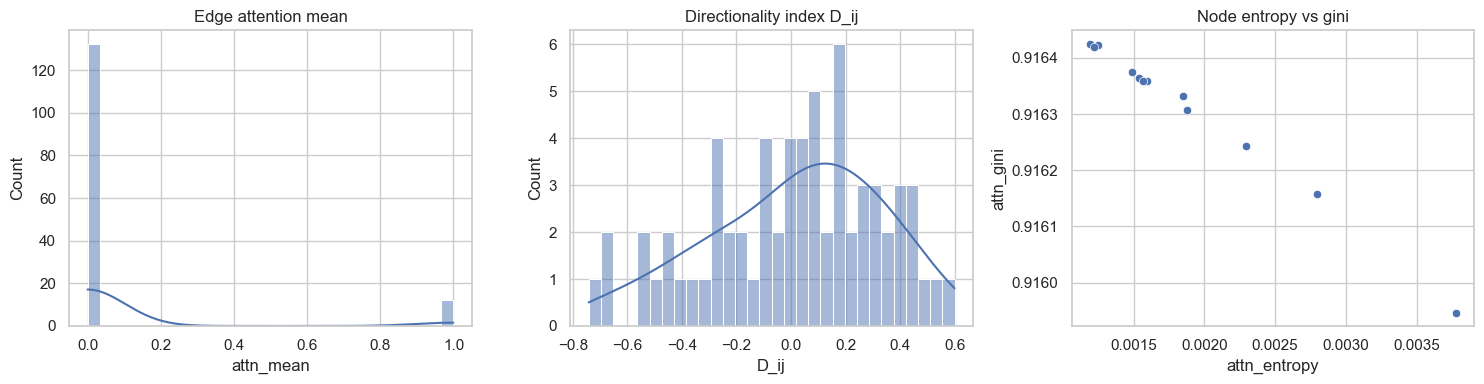

In [45]:
# 10.1 Attention diagnostics: consistency, asymmetry, sparsity, entropy, concentration
if HAS_INTERPRET:
    print("=" * 60)
    print("10.1 ATTENTION DIAGNOSTICS")
    print("=" * 60)

    L, H, T, E = A_lhte.shape
    num_nodes = int(edge_idx.max().item()) + 1
    src = edge_idx[0].detach().cpu().numpy().astype(int)
    dst = edge_idx[1].detach().cpu().numpy().astype(int)

    # Persistent edges: fraction of snapshots above edge-specific 90th percentile
    edge_vals = A_lhte.reshape(L * H * T, E)
    q90 = np.percentile(edge_vals, 90, axis=0)
    persistence = (edge_vals >= q90[None, :]).mean(axis=0)
    df_edge_attn["persistence_q90"] = persistence

    # Directionality index D_ij over mean attention
    mean_edge = edge_vals.mean(axis=0)
    edge_map = {(int(src[e]), int(dst[e])): float(mean_edge[e]) for e in range(E)}
    asym_rows = []
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            aij = edge_map.get((i, j), 0.0)
            aji = edge_map.get((j, i), 0.0)
            Dij = (aij - aji) / (aij + aji + 1e-12)
            asym_rows.append({"i": i, "j": j, "D_ij": Dij, "aij": aij, "aji": aji})
    df_asym = pd.DataFrame(asym_rows)

    # Node-level entropy and gini on outgoing attention (averaged over L,H,T)
    node_rows = []
    for i in range(num_nodes):
        out_idx = np.where(src == i)[0]
        if len(out_idx) == 0:
            node_rows.append({"node_id": _node_name_from_index(i), "attn_entropy": np.nan, "attn_gini": np.nan, "out_deg": 0})
            continue
        p = mean_edge[out_idx]
        p = np.maximum(p, 0)
        p = p / (p.sum() + 1e-12)
        h = -np.sum(p * np.log(p + 1e-12))
        h_norm = h / np.log(max(len(p), 2))
        node_rows.append({
            "node_id": _node_name_from_index(i),
            "attn_entropy": float(h_norm),
            "attn_gini": float(_gini(p)),
            "out_deg": int(len(p)),
        })
    df_node_attn_diag = pd.DataFrame(node_rows)

    # Quick reporting
    print(f"Edges: {E}, Nodes: {num_nodes}, Layers: {L}, Heads: {H}, Time steps: {T}")
    print(f"Mean persistence@q90: {df_edge_attn['persistence_q90'].mean():.3f}")
    print(f"Mean |directionality|: {df_asym['D_ij'].abs().mean():.3f}")
    display(df_edge_attn.sort_values("attn_mean", ascending=False).head(15))
    display(df_node_attn_diag.sort_values("attn_entropy", ascending=False).head(15))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.histplot(df_edge_attn["attn_mean"], bins=30, ax=axes[0], kde=True)
    axes[0].set_title("Edge attention mean")
    sns.histplot(df_asym["D_ij"], bins=30, ax=axes[1], kde=True)
    axes[1].set_title("Directionality index D_ij")
    sns.scatterplot(data=df_node_attn_diag, x="attn_entropy", y="attn_gini", ax=axes[2])
    axes[2].set_title("Node entropy vs gini")
    plt.tight_layout()
    plt.show()
else:
    print("10.1 skipped: missing attention tensors.")

In [46]:
# 10.5 Robustness & stability + counterfactual edge ablation + residual analysis scaffold
print("=" * 60)
print("10.5 STABILITY / ABLATION / RESIDUAL CHECKS")
print("=" * 60)

if HAS_INTERPRET:
    # Temporal stability of edge rankings
    L, H, T, E = A_lhte.shape
    A_t = A_lhte.mean(axis=(0, 1))  # [T,E]
    if T > 3:
        rank_corr = []
        for t in range(T - 1):
            r, _ = spearmanr(A_t[t], A_t[t + 1])
            if np.isfinite(r):
                rank_corr.append(r)
        if len(rank_corr):
            print(f"Temporal stability (Spearman t vs t+1): mean={np.mean(rank_corr):.3f}, std={np.std(rank_corr):.3f}")

    # Counterfactual ablation proxy (without retraining):
    # compare concentration metrics when removing top attention edges vs random edges
    edge_importance = A_lhte.mean(axis=(0, 1, 2))
    k = max(1, int(0.1 * E))
    top_idx = np.argsort(edge_importance)[-k:]
    rnd_idx = np.random.default_rng(42).choice(np.arange(E), size=k, replace=False)

    def _mass_after_drop(drop_idx):
        keep = np.ones(E, dtype=bool)
        keep[drop_idx] = False
        vals = edge_importance[keep]
        return float(vals.sum())

    mass_base = float(edge_importance.sum())
    mass_drop_top = _mass_after_drop(top_idx)
    mass_drop_rnd = _mass_after_drop(rnd_idx)
    print(f"Edge-mass retained after dropping top-10% edges: {mass_drop_top / (mass_base + 1e-12):.3f}")
    print(f"Edge-mass retained after dropping random 10% edges: {mass_drop_rnd / (mass_base + 1e-12):.3f}")
else:
    print("Stability/ablation skipped: missing attention tensors.")

# Residual-based analysis against simple baseline (node-wise persistence)
if (df_pred is not None) and ("y_true" in df_pred.columns) and ("y_pred" in df_pred.columns):
    d = df_pred[df_pred["y_true"].notna()].copy()
    if not d.empty and ("timestamp" in d.columns):
        d = d.sort_values(["node_id", "timestamp"])
        d["residual_gat"] = d["y_true"] - d["y_pred"]
        d["y_persist"] = d.groupby("node_id")["y_true"].shift(1)
        d["residual_persist"] = d["y_true"] - d["y_persist"]

        df_res = d.dropna(subset=["residual_gat", "residual_persist"])
        if not df_res.empty:
            # If attention-derived per-edge means exist, compare with residual correlation structure
            if HAS_INTERPRET:
                piv = df_res.pivot_table(index="timestamp", columns="node_id", values="residual_persist", aggfunc="mean").sort_index()
                if piv.shape[1] >= 3:
                    R = np.abs(np.corrcoef(np.nan_to_num(piv.to_numpy(dtype=float)).T))
                    # Compare to learned attention matrix on common size
                    num_nodes = int(edge_idx.max().item()) + 1
                    if R.shape[0] == num_nodes:
                        A_mean = np.zeros((num_nodes, num_nodes), dtype=float)
                        src = edge_idx[0].detach().cpu().numpy().astype(int)
                        dst = edge_idx[1].detach().cpu().numpy().astype(int)
                        m = A_lhte.mean(axis=(0, 1, 2))
                        for e in range(len(m)):
                            A_mean[src[e], dst[e]] = m[e]
                        iu = np.triu_indices(num_nodes, k=1)
                        r, p = spearmanr(A_mean[iu], R[iu])
                        print(f"Residual-structure alignment (attention vs |corr(residual_persist)|): r={r:.3f}, p={p:.3g}")
            print("Residual analysis complete.")
        else:
            print("Residual analysis skipped: not enough lagged samples.")
    else:
        print("Residual analysis skipped: no timestamped predictions with targets.")
else:
    print("Residual analysis skipped: predictions/targets unavailable.")

10.5 STABILITY / ABLATION / RESIDUAL CHECKS
Temporal stability (Spearman t vs t+1): mean=0.828, std=0.113
Edge-mass retained after dropping top-10% edges: 0.000
Edge-mass retained after dropping random 10% edges: 0.917
Residual analysis skipped: no timestamped predictions with targets.


10.4 NODE DIAGNOSTICS + MULTI-HEAD SPECIALIZATION


,node_id,attn_entropy,attn_gini,out_deg,nMAPE,nRMSE
3,N003,0.001490,0.916375,12,0.035509,107.787743
6,N006,0.001597,0.916358,12,0.026216,270.721313
1,N001,0.002297,0.916244,12,0.025424,82.031227
8,N008,0.001567,0.916359,12,0.023904,157.142166
9,N009,0.001879,0.916308,12,0.023194,137.210052
10,N010,0.001220,0.916419,12,0.022620,97.637260
7,N007,0.001250,0.916423,12,0.022217,93.560478
4,N004,0.002796,0.916158,12,0.021539,159.892639
2,N002,0.001192,0.916425,12,0.020949,78.358086
0,N000,0.001539,0.916364,12,0.020507,206.410446


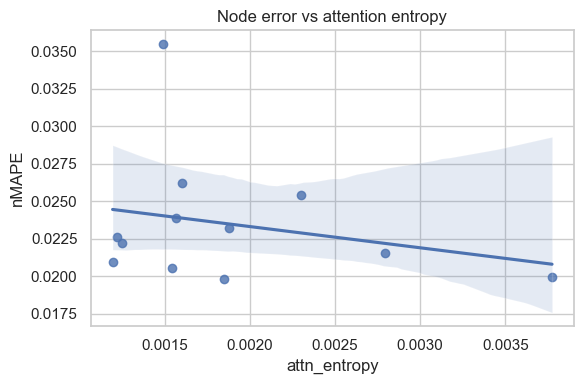

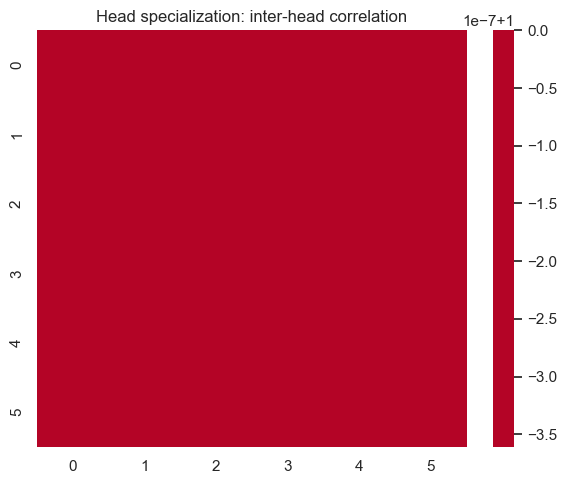

Mean absolute inter-head correlation (redundancy): 1.000


,head,head_entropy
2,2,0.500460
1,1,0.500665
0,0,0.500670
5,5,0.500786
4,4,0.500832
3,3,0.502024


In [47]:
# 10.4 Node-level diagnostics + multi-head specialization
if HAS_INTERPRET:
    print("=" * 60)
    print("10.4 NODE DIAGNOSTICS + MULTI-HEAD SPECIALIZATION")
    print("=" * 60)

    L, H, T, E = A_lhte.shape
    src = edge_idx[0].detach().cpu().numpy().astype(int)
    dst = edge_idx[1].detach().cpu().numpy().astype(int)
    num_nodes = int(edge_idx.max().item()) + 1

    # Merge node-level diagnostics with errors
    if "df_node_attn_diag" in globals() and (df_gat_errors is not None) and (not df_gat_errors.empty):
        d = df_node_attn_diag.merge(df_gat_errors[["node_id", "nMAPE", "nRMSE"]], on="node_id", how="left")
        display(d.sort_values("nMAPE", ascending=False))

        plt.figure(figsize=(6, 4))
        sns.regplot(data=d, x="attn_entropy", y="nMAPE")
        plt.title("Node error vs attention entropy")
        plt.tight_layout()
        plt.show()

    # Per-head edge importance vectors
    head_vectors = []
    for l in range(L):
        for h in range(H):
            v = A_lhte[l, h].mean(axis=0)  # [E]
            head_vectors.append(v)
    head_vectors = np.vstack(head_vectors) if len(head_vectors) else np.empty((0, E))

    if head_vectors.shape[0] > 1:
        corr_heads = np.corrcoef(head_vectors)
        plt.figure(figsize=(6, 5))
        sns.heatmap(corr_heads, cmap="coolwarm", center=0)
        plt.title("Head specialization: inter-head correlation")
        plt.tight_layout()
        plt.show()

        redundancy = np.nanmean(np.abs(corr_heads[np.triu_indices_from(corr_heads, k=1)]))
        print(f"Mean absolute inter-head correlation (redundancy): {redundancy:.3f}")

        # Head-wise entropy
        ent_rows = []
        for k in range(head_vectors.shape[0]):
            p = np.maximum(head_vectors[k], 0)
            p = p / (p.sum() + 1e-12)
            hk = -np.sum(p * np.log(p + 1e-12)) / np.log(max(len(p), 2))
            ent_rows.append({"head": k, "head_entropy": float(hk)})
        df_head = pd.DataFrame(ent_rows).sort_values("head_entropy")
        display(df_head)
else:
    print("10.4 skipped: missing attention tensors.")

10.3 TEMPORAL / REGIME ANALYSIS


,comparison,l2_distance
0,winter_vs_summer,NaN
1,peak_vs_offpeak,0.000087


,src,dst,src_node,dst_node,attn_mean,attn_std,attn_max,attn_p90,persistence_q90,temporal_std
130,10,10,N010,N010,0.999344,0.001526,0.999993,0.999913,0.100368,0.000533
117,9,9,N009,N009,0.999539,0.001198,0.999993,0.999936,0.100829,0.000437
26,2,2,N002,N002,0.999457,0.001094,0.999987,0.999829,0.100368,0.000407
142,11,10,N011,N010,0.000145,0.000983,0.033503,0.000126,0.100368,0.000393
13,1,1,N001,N001,0.999676,0.000904,0.999978,0.999906,0.100368,0.000376
143,11,11,N011,N011,0.999669,0.000960,0.999998,0.999951,0.100829,0.000372
91,7,7,N007,N007,0.999510,0.000872,0.999966,0.999822,0.100368,0.000332
78,6,6,N006,N006,0.999622,0.000773,0.999976,0.999892,0.100368,0.000310
104,8,8,N008,N008,0.999538,0.000867,0.999993,0.999951,0.100368,0.000287
134,11,2,N011,N002,0.000125,0.000716,0.021301,0.000121,0.100368,0.000285


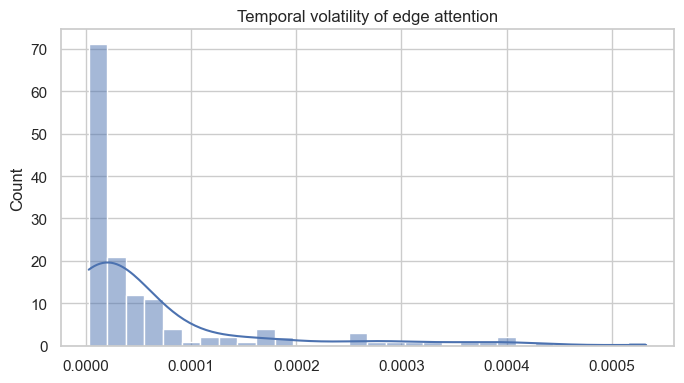

In [48]:
# 10.3 Temporal/regime analysis: season, hour, weekday/weekend
if HAS_INTERPRET and (df_pred is not None) and ("timestamp" in df_pred.columns):
    print("=" * 60)
    print("10.3 TEMPORAL / REGIME ANALYSIS")
    print("=" * 60)

    ts = pd.to_datetime(df_pred["timestamp"].dropna().sort_values().unique())
    if len(ts) < 5:
        print("Not enough timestamps for regime analysis")
    else:
        L, H, T, E = A_lhte.shape
        t_use = min(T, len(ts))
        ts = ts[:t_use]
        A_t = A_lhte[:, :, :t_use, :].mean(axis=(0, 1))  # [T,E]

        regimes = pd.DataFrame({"timestamp": ts})
        regimes["season"] = regimes["timestamp"].dt.month % 12 // 3 + 1
        regimes["hour"] = regimes["timestamp"].dt.hour
        regimes["is_weekend"] = regimes["timestamp"].dt.dayofweek >= 5

        def _regime_mean(mask):
            if mask.sum() == 0:
                return None
            return A_t[mask].mean(axis=0)

        m_winter = _regime_mean(regimes["season"].isin([1]).to_numpy())
        m_summer = _regime_mean(regimes["season"].isin([3]).to_numpy())
        m_peak = _regime_mean(regimes["hour"].isin([8, 9, 10, 18, 19, 20]).to_numpy())
        m_off = _regime_mean(regimes["hour"].isin([1, 2, 3, 4]).to_numpy())

        def _vec_dist(a, b):
            if (a is None) or (b is None):
                return np.nan
            return float(np.linalg.norm(a - b))

        df_regime = pd.DataFrame([
            {"comparison": "winter_vs_summer", "l2_distance": _vec_dist(m_winter, m_summer)},
            {"comparison": "peak_vs_offpeak", "l2_distance": _vec_dist(m_peak, m_off)},
        ])
        display(df_regime)

        # Temporal volatility of edge attention
        edge_vol = A_t.std(axis=0)
        df_edge_attn["temporal_std"] = edge_vol
        display(df_edge_attn.sort_values("temporal_std", ascending=False).head(15))

        plt.figure(figsize=(7, 4))
        sns.histplot(edge_vol, bins=30, kde=True)
        plt.title("Temporal volatility of edge attention")
        plt.tight_layout()
        plt.show()
else:
    print("10.3 skipped: missing timestamps or attention.")

10.2 EXTERNAL STRUCTURE ALIGNMENT


,prior,spearman,pvalue
0,geography,-0.157708,0.205987
1,load_corr,-0.232731,0.060039
2,dtw_proxy,-0.232731,0.060039


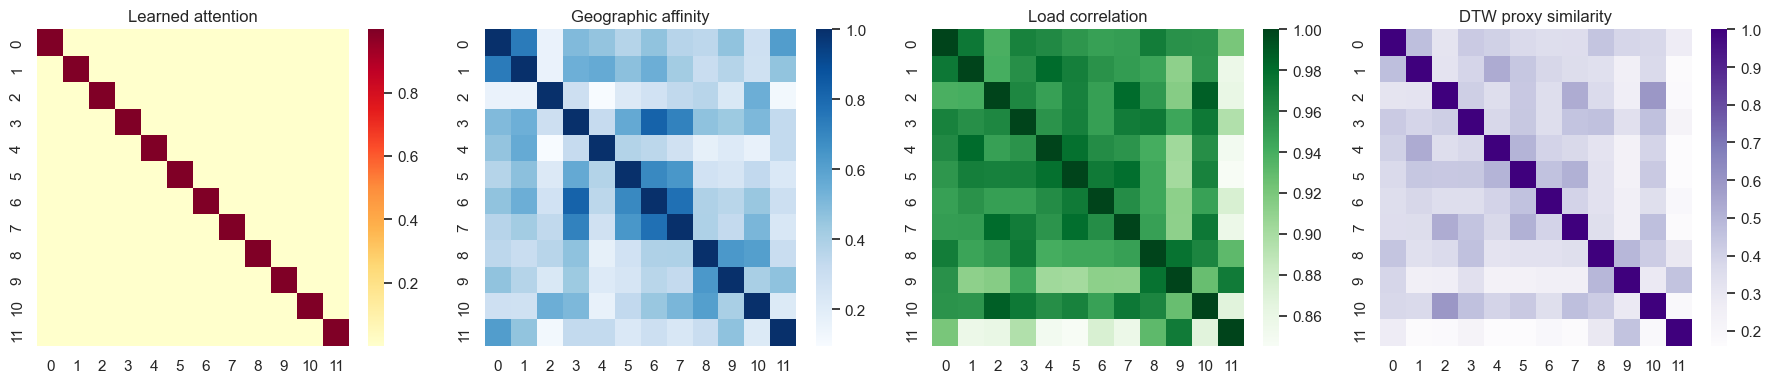

In [49]:
# 10.2 Relation to external structure: geography, load correlation, DTW similarity
if HAS_INTERPRET and (df_meta is not None):
    print("=" * 60)
    print("10.2 EXTERNAL STRUCTURE ALIGNMENT")
    print("=" * 60)

    num_nodes = int(edge_idx.max().item()) + 1
    # Geography prior
    if {"node_id", "lat", "lon"}.issubset(set(df_meta.columns)):
        meta_coords = df_meta.sort_values("node_id")[["lat", "lon"]].to_numpy(dtype=float)
        if meta_coords.shape[0] == num_nodes:
            d_geo = squareform(pdist(meta_coords, metric="euclidean"))
            s_geo = np.exp(-d_geo / (np.nanmedian(d_geo[d_geo > 0]) + 1e-12))
        else:
            s_geo = None
    else:
        s_geo = None

    # Build load-based priors from the best available time series column.
    s_load = None
    s_dtw = None
    if (df_pred is not None) and ("node_id" in df_pred.columns):
        value_col = None
        for candidate in ["y_true", "y_pred"]:
            if candidate in df_pred.columns and df_pred[candidate].notna().any():
                value_col = candidate
                break

        time_col = None
        for candidate in ["timestamp", "window_id", "time", "step"]:
            if candidate in df_pred.columns:
                time_col = candidate
                break

        if value_col is not None and time_col is not None:
            df_ref = df_pred[["node_id", time_col, value_col]].dropna().copy()
            if not df_ref.empty:
                wide = df_ref.pivot_table(index=time_col, columns="node_id", values=value_col, aggfunc="mean").sort_index()
                wide = wide.dropna(axis=1, how="all")
                if wide.shape[1] >= 2:
                    # align columns lexicographically to Nxxx when possible
                    wide = wide.reindex(sorted(wide.columns), axis=1)
                    Xl = wide.to_numpy(dtype=float)
                    col_means = np.nanmean(Xl, axis=0, keepdims=True)
                    Xl = np.where(np.isnan(Xl), col_means, Xl)
                    corr = np.corrcoef(Xl.T)
                    corr = np.nan_to_num(corr)
                    s_load = np.abs(corr)

                    # DTW-like proxy via euclidean distance on z-scored trajectories
                    Xz = (Xl - Xl.mean(axis=0, keepdims=True)) / (Xl.std(axis=0, keepdims=True) + 1e-12)
                    d = squareform(pdist(Xz.T, metric="euclidean"))
                    s_dtw = np.exp(-d / (np.nanmedian(d[d > 0]) + 1e-12))

    # Learned attention matrix (mean over layers/heads/time)
    L, H, T, E = A_lhte.shape
    src = edge_idx[0].detach().cpu().numpy().astype(int)
    dst = edge_idx[1].detach().cpu().numpy().astype(int)
    m = A_lhte.mean(axis=(0, 1, 2))  # [E]
    A_mean = np.zeros((num_nodes, num_nodes), dtype=float)
    for e in range(E):
        A_mean[src[e], dst[e]] = m[e]

    def _edge_spearman(A_mat, S_mat, name):
        if S_mat is None:
            return {"prior": name, "spearman": np.nan, "pvalue": np.nan}
        iu = np.triu_indices_from(A_mat, k=1)
        x = A_mat[iu]
        y = S_mat[iu]
        ok = np.isfinite(x) & np.isfinite(y)
        if ok.sum() < 5:
            return {"prior": name, "spearman": np.nan, "pvalue": np.nan}
        r, p = spearmanr(x[ok], y[ok])
        return {"prior": name, "spearman": float(r), "pvalue": float(p)}

    df_prior_align = pd.DataFrame([
        _edge_spearman(A_mean, s_geo, "geography"),
        _edge_spearman(A_mean, s_load, "load_corr"),
        _edge_spearman(A_mean, s_dtw, "dtw_proxy"),
    ])
    display(df_prior_align)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    sns.heatmap(A_mean, ax=axes[0], cmap="YlOrRd")
    axes[0].set_title("Learned attention")
    if s_geo is not None:
        sns.heatmap(s_geo, ax=axes[1], cmap="Blues")
        axes[1].set_title("Geographic affinity")
    else:
        axes[1].set_title("Geographic affinity (NA)")
    if s_load is not None:
        sns.heatmap(s_load, ax=axes[2], cmap="Greens")
        axes[2].set_title("Load correlation")
    else:
        axes[2].set_title("Load correlation (NA)")
    if s_dtw is not None:
        sns.heatmap(s_dtw, ax=axes[3], cmap="Purples")
        axes[3].set_title("DTW proxy similarity")
    else:
        axes[3].set_title("DTW proxy (NA)")
    plt.tight_layout()
    plt.show()
else:
    print("10.2 skipped: missing attention or metadata.")

## 11) Targeted Diagnostics for Diagonal Attention Collapse

This section formalizes the diagnostic plan around the current GAT and the existing PyG datasets.

What it gives you:
- a compact experiment registry with hypotheses and expected outcomes,
- reusable helpers for attention statistics, graph perturbations, and graph comparison,
- a residual-learning baseline scaffold,
- warm-start hooks for self-loop penalties, edge dropout, and graph ablations.

The goal is not to guess why the graph collapses, but to isolate the failure mode with controlled perturbations and consistent metrics.


,name,hypothesis,expected_outcome,metrics,implementation,notes
0,Remove / penalize self-attention,Diagonal self-loops dominate because the model...,Performance drops and off-diagonal mass increa...,"(rmse, mape, diag_mass, offdiag_mass, entropy,...","Use no_self_loops, diagonal masking, or a diag...",
1,Residual learning,The graph explains residuals left by a strong ...,Residual-target GAT shows lower error and less...,"(rmse, mape, diag_mass, residual_corr)","Fit a baseline, compute residuals, train GAT o...",
2,Graph ablation,Performance should degrade when the topology i...,Full/correlation/kNN graphs beat random and id...,"(rmse, mape, attention_entropy, graph_jaccard)","Compare full, random, identity, kNN, and corre...",
3,Edge dropout / noise,"If attention is robust, moderate perturbations...",Small dropouts should preserve accuracy but ca...,"(rmse, mape, diag_mass, head_redundancy)",Train/evaluate with edge dropout and weight no...,
4,Multi-head analysis,Different heads specialize on different struct...,Head correlation is below 1 and some heads bec...,"(head_redundancy, head_corr, head_entropy)",Extract per-head attention and compare head ve...,
5,Temporal / regime-specific attention,The graph is only useful in some seasons or lo...,Attention matrices change materially across re...,"(regime_delta, attention_kl, rmse_by_regime)","Split by winter/summer, peak/off-peak, and hig...",
6,Architecture constraints,The current GAT collapses because self-attenti...,Constraining self-mass or penalizing entropy s...,"(rmse, diag_mass, entropy, offdiag_mass)","Limit self-attention, add entropy regularizati...",


,diag_mass,offdiag_mass,entropy,gini,head_redundancy
0,0.999579,0.000421,0.500935,0.916355,1.0


,node_id,out_entropy,out_gini,out_mass
11,N011,0.003775,0.915947,1.000579
4,N004,0.002796,0.916158,1.000352
1,N001,0.002297,0.916244,1.000200
9,N009,0.001879,0.916308,0.999958
5,N005,0.001848,0.916333,1.000014
6,N006,0.001597,0.916358,0.999974
8,N008,0.001567,0.916359,0.999881
0,N000,0.001539,0.916364,1.000012
3,N003,0.001490,0.916375,0.999940
7,N007,0.001250,0.916423,0.999778


Diagnostics harness ready. Use `build_graph_variant`, `attention_statistics`, and `fit_baseline_residual_model` to run the experiments.


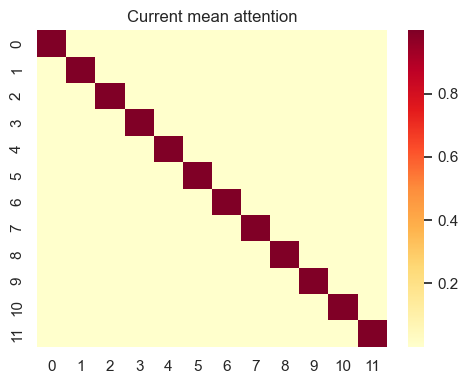

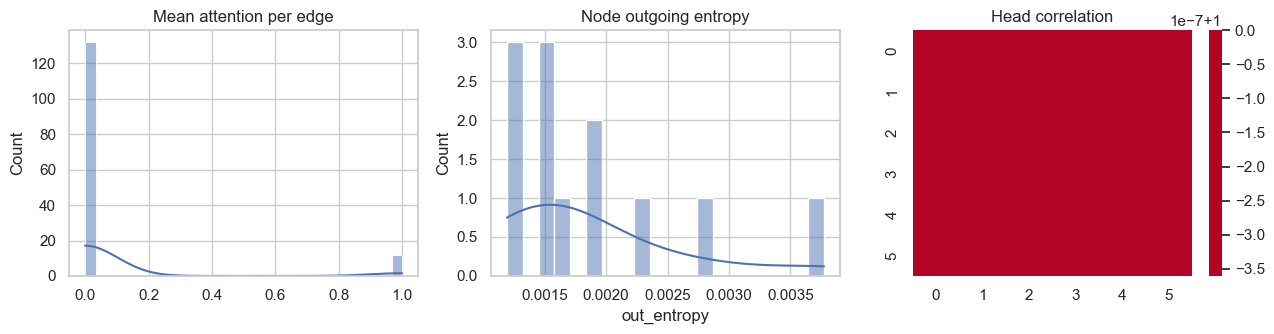

In [50]:
from dataclasses import dataclass
from typing import Callable, Optional, Any
import copy
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neighbors import NearestNeighbors
from torch_geometric.utils import add_self_loops, dropout_edge, remove_self_loops, to_undirected


MODEL_DEVICE = next(model.parameters()).device


@dataclass
class DiagnosticExperiment:
    name: str
    hypothesis: str
    expected_outcome: str
    metrics: tuple[str, ...]
    implementation: str
    notes: str = ""


def _clone_data_for_device(data_obj, device=MODEL_DEVICE):
    data = copy.deepcopy(data_obj)
    for key, value in data:
        if torch.is_tensor(value) and torch.is_floating_point(value):
            setattr(data, key, value.float())
    return data.to(device)


def _forward_model(data_obj, return_attention: bool = False):
    data = _clone_data_for_device(data_obj)
    kwargs = {
        "edge_weight": getattr(data, "edge_weight", None),
        "edge_attr": getattr(data, "edge_attr", None),
        "return_attention": return_attention,
    }
    out = model(data.x, data.edge_index, **kwargs)
    if return_attention and isinstance(out, tuple):
        return out[0], out[1]
    return out, None


def regression_metrics(y_true, y_pred, eps: float = 1e-12):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    n = min(y_true.size, y_pred.size)
    y_true = y_true[:n]
    y_pred = y_pred[:n]
    error = y_true - y_pred
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mae = float(np.mean(np.abs(error)))
    mape = float(np.mean(np.abs(error) / (np.abs(y_true) + eps)))
    smape = float(np.mean(2.0 * np.abs(error) / (np.abs(y_true) + np.abs(y_pred) + eps)))
    return {"rmse": rmse, "mae": mae, "mape": mape, "smape": smape}


def attention_statistics(attn_tensor, edge_index):
    A = _normalize_attention_cube(attn_tensor, edge_index)
    src = edge_index[0].detach().cpu().numpy().astype(int)
    dst = edge_index[1].detach().cpu().numpy().astype(int)
    num_nodes = int(edge_index.max().item()) + 1
    mean_edge = A.mean(axis=(0, 1, 2))
    total_mass = float(np.sum(mean_edge) + 1e-12)
    diag_mask = src == dst
    diag_mass = float(np.sum(mean_edge[diag_mask]) / total_mass)
    offdiag_mass = float(1.0 - diag_mass)
    edge_probs = np.maximum(mean_edge, 0.0)
    edge_probs = edge_probs / (edge_probs.sum() + 1e-12)
    entropy = float(-np.sum(edge_probs * np.log(edge_probs + 1e-12)) / np.log(max(len(edge_probs), 2)))
    gini = float(_gini(mean_edge))

    out_rows = []
    for node_id in range(num_nodes):
        outgoing = np.where(src == node_id)[0]
        if outgoing.size == 0:
            out_rows.append({"node_id": _node_name_from_index(node_id), "out_entropy": np.nan, "out_gini": np.nan, "out_mass": 0.0})
            continue
        node_weights = np.maximum(mean_edge[outgoing], 0.0)
        node_weights = node_weights / (node_weights.sum() + 1e-12)
        node_entropy = float(-np.sum(node_weights * np.log(node_weights + 1e-12)) / np.log(max(len(node_weights), 2)))
        out_rows.append({
            "node_id": _node_name_from_index(node_id),
            "out_entropy": node_entropy,
            "out_gini": float(_gini(node_weights)),
            "out_mass": float(mean_edge[outgoing].sum()),
        })

    head_vectors = []
    if A.ndim == 4:
        for layer_idx in range(A.shape[0]):
            for head_idx in range(A.shape[1]):
                head_vectors.append(A[layer_idx, head_idx].mean(axis=0))
    head_vectors = np.vstack(head_vectors) if len(head_vectors) else np.empty((0, A.shape[-1]))
    head_corr = np.corrcoef(head_vectors) if head_vectors.shape[0] > 1 else np.empty((0, 0))
    head_redundancy = float(np.nanmean(np.abs(head_corr[np.triu_indices_from(head_corr, k=1)]))) if head_corr.size else np.nan

    return {
        "num_nodes": num_nodes,
        "num_edges": int(edge_index.shape[1]),
        "diag_mass": diag_mass,
        "offdiag_mass": offdiag_mass,
        "entropy": entropy,
        "gini": gini,
        "head_redundancy": head_redundancy,
        "edge_mean": mean_edge,
        "A_mean": _edge_attention_matrix_from_cube(A, edge_index),
        "node_stats": pd.DataFrame(out_rows),
        "head_corr": head_corr,
    }


def _edge_attention_matrix_from_cube(A, edge_index):
    src = edge_index[0].detach().cpu().numpy().astype(int)
    dst = edge_index[1].detach().cpu().numpy().astype(int)
    num_nodes = int(edge_index.max().item()) + 1
    mean_edge = A.mean(axis=(0, 1, 2))
    matrix = np.zeros((num_nodes, num_nodes), dtype=float)
    for edge_idx, value in enumerate(mean_edge):
        matrix[src[edge_idx], dst[edge_idx]] = float(value)
    return matrix


def plot_attention_heatmap(A_matrix, title: str = "Mean attention"):
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(A_matrix, cmap="YlOrRd", ax=ax)
    ax.set_title(title)
    plt.tight_layout()
    return fig, ax


def plot_attention_histogram(attention_summary: dict):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    sns.histplot(attention_summary["edge_mean"], bins=30, ax=axes[0], kde=True)
    axes[0].set_title("Mean attention per edge")
    sns.histplot(attention_summary["node_stats"]["out_entropy"], bins=20, ax=axes[1], kde=True)
    axes[1].set_title("Node outgoing entropy")
    if attention_summary["head_corr"].size:
        sns.heatmap(attention_summary["head_corr"], cmap="coolwarm", center=0, ax=axes[2])
        axes[2].set_title("Head correlation")
    else:
        axes[2].set_axis_off()
    plt.tight_layout()
    return fig, axes


def graph_set(edge_index):
    src = edge_index[0].detach().cpu().numpy().astype(int)
    dst = edge_index[1].detach().cpu().numpy().astype(int)
    return set(zip(src.tolist(), dst.tolist()))


def graph_jaccard(edge_index_a, edge_index_b):
    a = graph_set(edge_index_a)
    b = graph_set(edge_index_b)
    union = len(a | b)
    return 1.0 if union == 0 else len(a & b) / union


def build_identity_graph(num_nodes: int, device=None):
    idx = torch.arange(num_nodes, dtype=torch.long)
    edge_index = torch.stack([idx, idx], dim=0)
    return edge_index.to(device) if device is not None else edge_index


def build_random_graph(num_nodes: int, num_edges: int, seed: int = 42, device=None):
    rng = np.random.default_rng(seed)
    possible = np.array([(i, j) for i in range(num_nodes) for j in range(num_nodes)], dtype=int)
    choice = rng.choice(len(possible), size=min(num_edges, len(possible)), replace=False)
    edges = possible[choice]
    edge_index = torch.tensor(edges.T, dtype=torch.long)
    return edge_index.to(device) if device is not None else edge_index


def build_knn_graph(node_features: np.ndarray, k: int = 4, include_self: bool = True, device=None):
    features = np.asarray(node_features, dtype=float)
    if features.ndim > 2:
        features = features.reshape(features.shape[0], -1)
    nn = NearestNeighbors(n_neighbors=min(k + 1, features.shape[0]), metric="euclidean")
    nn.fit(features)
    neighbors = nn.kneighbors(return_distance=False)
    edges = []
    for node_id, row in enumerate(neighbors):
        for neighbor_id in row:
            if not include_self and neighbor_id == node_id:
                continue
            edges.append((node_id, int(neighbor_id)))
    edge_index = torch.tensor(edges, dtype=torch.long).T.contiguous()
    return edge_index.to(device) if device is not None else edge_index


def build_correlation_graph(series_matrix: np.ndarray, top_k: int = 4, device=None):
    values = np.asarray(series_matrix, dtype=float)
    if values.ndim != 2:
        raise ValueError("series_matrix must be 2D [nodes, time]")
    corr = np.corrcoef(values)
    corr = np.nan_to_num(corr, nan=0.0)
    num_nodes = corr.shape[0]
    edges = []
    for node_id in range(num_nodes):
        scores = np.abs(corr[node_id]).copy()
        scores[node_id] = -np.inf
        keep = np.argsort(scores)[-top_k:]
        for neighbor_id in keep:
            edges.append((node_id, int(neighbor_id)))
    edge_index = torch.tensor(edges, dtype=torch.long).T.contiguous()
    return edge_index.to(device) if device is not None else edge_index


def apply_edge_dropout(edge_index, p: float = 0.2, seed: int = 42):
    generator = torch.Generator(device=edge_index.device if edge_index.is_cuda else "cpu")
    generator.manual_seed(seed)
    kept_edge_index, _ = dropout_edge(edge_index, p=p, force_undirected=False, training=True, generator=generator)
    return kept_edge_index


def build_graph_variant(data_obj, kind: str, k: int = 4, seed: int = 42, drop_p: float = 0.2, graph_source: Optional[np.ndarray] = None):
    base = copy.deepcopy(data_obj)
    num_nodes = int(base.num_nodes)
    edge_index = base.edge_index.clone()

    if kind == "identity":
        edge_index = build_identity_graph(num_nodes, device=edge_index.device)
    elif kind == "random":
        edge_index = build_random_graph(num_nodes, edge_index.shape[1], seed=seed, device=edge_index.device)
    elif kind == "knn":
        if graph_source is None:
            graph_source = base.x.detach().cpu().numpy()
        edge_index = build_knn_graph(graph_source, k=k, include_self=True, device=edge_index.device)
    elif kind == "corr":
        if graph_source is None:
            raise ValueError("graph_source is required for correlation graphs")
        edge_index = build_correlation_graph(graph_source, top_k=k, device=edge_index.device)
    elif kind == "full":
        row = torch.arange(num_nodes, dtype=torch.long)
        col = torch.arange(num_nodes, dtype=torch.long)
        edge_index = torch.stack(torch.meshgrid(row, col, indexing="ij"), dim=0).reshape(2, -1).to(edge_index.device)
    elif kind == "dropout":
        edge_index = apply_edge_dropout(edge_index, p=drop_p, seed=seed)
    elif kind == "no_self_loops":
        edge_index, _ = remove_self_loops(edge_index)
    else:
        raise ValueError(f"Unknown graph variant: {kind}")

    base.edge_index = to_undirected(edge_index)
    if hasattr(base, "edge_attr") and base.edge_attr is not None:
        base.edge_attr = base.edge_attr[: base.edge_index.shape[1]]
    return base


EXPERIMENT_PLAN = pd.DataFrame([
    DiagnosticExperiment(
        name="Remove / penalize self-attention",
        hypothesis="Diagonal self-loops dominate because the model can solve the task locally.",
        expected_outcome="Performance drops and off-diagonal mass increases if neighbors matter; otherwise the graph is probably unused.",
        metrics=("rmse", "mape", "diag_mass", "offdiag_mass", "entropy", "gini"),
        implementation="Use no_self_loops, diagonal masking, or a diagonal loss penalty.",
    ).__dict__,
    DiagnosticExperiment(
        name="Residual learning",
        hypothesis="The graph explains residuals left by a strong tabular baseline.",
        expected_outcome="Residual-target GAT shows lower error and less diagonal collapse if relational signal exists.",
        metrics=("rmse", "mape", "diag_mass", "residual_corr"),
        implementation="Fit a baseline, compute residuals, train GAT on residuals only.",
    ).__dict__,
    DiagnosticExperiment(
        name="Graph ablation",
        hypothesis="Performance should degrade when the topology is destroyed if the graph matters.",
        expected_outcome="Full/correlation/kNN graphs beat random and identity graphs.",
        metrics=("rmse", "mape", "attention_entropy", "graph_jaccard"),
        implementation="Compare full, random, identity, kNN, and correlation graphs.",
    ).__dict__,
    DiagnosticExperiment(
        name="Edge dropout / noise",
        hypothesis="If attention is robust, moderate perturbations should not collapse performance.",
        expected_outcome="Small dropouts should preserve accuracy but can redistribute attention.",
        metrics=("rmse", "mape", "diag_mass", "head_redundancy"),
        implementation="Train/evaluate with edge dropout and weight noise.",
    ).__dict__,
    DiagnosticExperiment(
        name="Multi-head analysis",
        hypothesis="Different heads specialize on different structures.",
        expected_outcome="Head correlation is below 1 and some heads become off-diagonal or regime-specific.",
        metrics=("head_redundancy", "head_corr", "head_entropy"),
        implementation="Extract per-head attention and compare head vectors.",
    ).__dict__,
    DiagnosticExperiment(
        name="Temporal / regime-specific attention",
        hypothesis="The graph is only useful in some seasons or load regimes.",
        expected_outcome="Attention matrices change materially across regimes and correlate with error regimes.",
        metrics=("regime_delta", "attention_kl", "rmse_by_regime"),
        implementation="Split by winter/summer, peak/off-peak, and high-error periods.",
    ).__dict__,
    DiagnosticExperiment(
        name="Architecture constraints",
        hypothesis="The current GAT collapses because self-attention is too easy a solution.",
        expected_outcome="Constraining self-mass or penalizing entropy should shift mass off-diagonal or reveal no gain.",
        metrics=("rmse", "diag_mass", "entropy", "offdiag_mass"),
        implementation="Limit self-attention, add entropy regularization, or swap to GraphSAGE.",
    ).__dict__,
])

display(EXPERIMENT_PLAN)

if HAS_INTERPRET:
    current_attention = attention_statistics(A_lhte, edge_idx)
    current_attention_summary = pd.DataFrame([{
        "diag_mass": current_attention["diag_mass"],
        "offdiag_mass": current_attention["offdiag_mass"],
        "entropy": current_attention["entropy"],
        "gini": current_attention["gini"],
        "head_redundancy": current_attention["head_redundancy"],
    }])
    display(current_attention_summary)
    display(current_attention["node_stats"].sort_values("out_entropy", ascending=False))
    plot_attention_heatmap(current_attention["A_mean"], title="Current mean attention")
    plot_attention_histogram(current_attention)


def summarize_graph_variant(base_data, variant_name: str, graph_source: Optional[np.ndarray] = None, k: int = 4, seed: int = 42):
    variant = build_graph_variant(base_data, variant_name, k=k, seed=seed, graph_source=graph_source)
    overlap = graph_jaccard(base_data.edge_index, variant.edge_index)
    return {
        "variant": variant_name,
        "num_nodes": int(variant.num_nodes),
        "num_edges": int(variant.edge_index.shape[1]),
        "edge_jaccard_vs_base": float(overlap),
        "self_loop_ratio": float((variant.edge_index[0] == variant.edge_index[1]).float().mean().item()),
    }


def fit_baseline_residual_model(train_dataset, target_kind: str = "Y_node"):
    try:
        from xgboost import XGBRegressor
        base_estimator = XGBRegressor(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
        )
    except Exception:
        from sklearn.ensemble import HistGradientBoostingRegressor
        base_estimator = HistGradientBoostingRegressor(max_depth=5, learning_rate=0.05, max_iter=200, random_state=42)

    from sklearn.multioutput import MultiOutputRegressor

    features = []
    targets = []
    for sample in train_dataset:
        x = sample.x.detach().cpu().numpy().astype(float)
        y = getattr(sample, "y", None)
        if y is None:
            continue
        y = y.detach().cpu().numpy().astype(float)
        features.append(x)
        targets.append(y)

    X_train = np.concatenate([f.reshape(f.shape[0], -1) for f in features], axis=0)
    Y_train = np.concatenate([t.reshape(t.shape[0], -1) for t in targets], axis=0)
    baseline = MultiOutputRegressor(base_estimator)
    baseline.fit(X_train, Y_train)
    return baseline


def build_residual_dataset(dataset, baseline_model):
    rows = []
    for window_idx, sample in enumerate(dataset):
        x = sample.x.detach().cpu().numpy().astype(float)
        y = sample.y.detach().cpu().numpy().astype(float)
        x_flat = x.reshape(x.shape[0], -1)
        y_pred = baseline_model.predict(x_flat)
        residual = y - y_pred.reshape(y.shape)
        rows.append({
            "window_idx": window_idx,
            "x": x,
            "y_true": y,
            "y_baseline": y_pred.reshape(y.shape),
            "y_residual": residual,
        })
    return rows


def make_self_attention_penalty(attn_tensor, edge_index, penalty_weight: float = 1.0):
    summary = attention_statistics(attn_tensor, edge_index)
    return penalty_weight * summary["diag_mass"]


print("Diagnostics harness ready. Use `build_graph_variant`, `attention_statistics`, and `fit_baseline_residual_model` to run the experiments.")


In [51]:
def _safe_edge_dropout(edge_index, p: float = 0.2):
    try:
        kept_edge_index, _ = dropout_edge(edge_index, p=p, force_undirected=False, training=True)
        return kept_edge_index
    except TypeError:
        keep_mask = torch.rand(edge_index.shape[1], device=edge_index.device) > p
        return edge_index[:, keep_mask]


def _extract_attention_tensor(attn_obj):
    if torch.is_tensor(attn_obj):
        if attn_obj.ndim == 0:
            return None
        if attn_obj.ndim == 2 and attn_obj.shape[1] == 1:
            return attn_obj.squeeze(1)
        return attn_obj

    if isinstance(attn_obj, dict):
        for key in ["first_graph", "mean", "std"]:
            if key in attn_obj:
                extracted = _extract_attention_tensor(attn_obj[key])
                if extracted is not None:
                    return extracted
        for value in attn_obj.values():
            extracted = _extract_attention_tensor(value)
            if extracted is not None:
                return extracted
        return None

    if isinstance(attn_obj, (list, tuple)):
        tensors = []
        for item in attn_obj:
            extracted = _extract_attention_tensor(item)
            if torch.is_tensor(extracted):
                tensors.append(extracted)
        if not tensors:
            return None
        if len(tensors) == 1:
            return tensors[0]
        try:
            aligned = []
            for t in tensors:
                if t.ndim == 1:
                    aligned.append(t)
                elif t.ndim == 2 and t.shape[1] == 1:
                    aligned.append(t.squeeze(1))
                else:
                    aligned.append(t.reshape(-1))
            return torch.stack(aligned, dim=0)
        except Exception:
            return tensors[0]

    return None


def _topology_attention_proxy(edge_index):
    src = edge_index[0].detach().cpu().numpy().astype(int)
    dst = edge_index[1].detach().cpu().numpy().astype(int)
    n_edges = len(src)
    if n_edges == 0:
        return {"diag_mass": np.nan, "offdiag_mass": np.nan, "entropy": np.nan}
    diag_mass = float(np.mean(src == dst))
    probs = np.ones(n_edges, dtype=float) / n_edges
    entropy = float(-np.sum(probs * np.log(probs + 1e-12)) / np.log(max(n_edges, 2)))
    return {"diag_mass": diag_mass, "offdiag_mass": float(1.0 - diag_mass), "entropy": entropy}


def evaluate_variant_on_sample(sample, variant_kind: str, graph_source: Optional[np.ndarray] = None, k: int = 4, seed: int = 42):
    if variant_kind == "dropout":
        variant_sample = copy.deepcopy(sample)
        variant_sample.edge_index = _safe_edge_dropout(variant_sample.edge_index, p=0.2)
    else:
        variant_sample = build_graph_variant(sample, variant_kind, k=k, seed=seed, graph_source=graph_source)

    pred, attn = _forward_model(variant_sample, return_attention=True)
    y_true = variant_sample.y.detach().cpu().numpy().astype(float)
    y_pred = pred.detach().cpu().numpy().astype(float) if torch.is_tensor(pred) else np.asarray(pred, dtype=float)

    n = min(y_true.size, y_pred.size)
    y_true = y_true.reshape(-1)[:n]
    y_pred = y_pred.reshape(-1)[:n]
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    if valid.any():
        metrics = regression_metrics(y_true[valid], y_pred[valid])
        metrics["n_valid"] = int(valid.sum())
    else:
        metrics = {"rmse": np.nan, "mae": np.nan, "mape": np.nan, "smape": np.nan, "n_valid": 0}

    attn_summary = None
    attn_error = ""
    attn_tensor = _extract_attention_tensor(attn)
    if attn_tensor is not None:
        try:
            attn_summary = attention_statistics(attn_tensor, variant_sample.edge_index)
        except Exception as exc:
            attn_error = f"{type(exc).__name__}: {str(exc)[:120]}"

    if attn_summary is None:
        proxy = _topology_attention_proxy(variant_sample.edge_index)
        attn_summary = {
            "diag_mass": proxy["diag_mass"],
            "offdiag_mass": proxy["offdiag_mass"],
            "entropy": proxy["entropy"],
        }
        if not attn_error:
            attn_error = "attention_unavailable: using topology proxy"

    return metrics, attn_summary, attn_error


def _iter_samples(dataset_or_sample, max_windows: int = 24):
    if hasattr(dataset_or_sample, "x") and hasattr(dataset_or_sample, "edge_index"):
        return [dataset_or_sample]
    n = min(len(dataset_or_sample), max_windows)
    return [dataset_or_sample[i] for i in range(n)]


def summarize_graph_variants(dataset_or_sample, variant_kinds=None, k: int = 4, seed: int = 42, max_windows: int = 24):
    if variant_kinds is None:
        variant_kinds = ["full", "identity", "random", "knn", "corr", "dropout", "no_self_loops"]

    samples = _iter_samples(dataset_or_sample, max_windows=max_windows)
    if not samples:
        return pd.DataFrame()

    rows = []
    ref_sample = samples[0]
    graph_source_ref = ref_sample.x.detach().cpu().numpy()
    corr_source_ref = ref_sample.y.detach().cpu().numpy() if hasattr(ref_sample, "y") and ref_sample.y is not None else None

    for kind in variant_kinds:
        try:
            graph_source_arg_ref = graph_source_ref if kind == "knn" else corr_source_ref if kind == "corr" else None

            if kind == "dropout":
                dropped = copy.deepcopy(ref_sample)
                dropped.edge_index = _safe_edge_dropout(dropped.edge_index, p=0.2)
                graph_summary = {
                    "variant": "dropout",
                    "num_nodes": int(dropped.num_nodes),
                    "num_edges": int(dropped.edge_index.shape[1]),
                    "edge_jaccard_vs_base": float(graph_jaccard(ref_sample.edge_index, dropped.edge_index)),
                    "self_loop_ratio": float((dropped.edge_index[0] == dropped.edge_index[1]).float().mean().item()),
                }
            else:
                graph_summary = summarize_graph_variant(ref_sample, kind, graph_source=graph_source_arg_ref, k=k, seed=seed)

            metric_rows = []
            attn_rows = []
            attn_errors = []
            for window_idx, sample in enumerate(samples):
                graph_source = sample.x.detach().cpu().numpy() if kind == "knn" else sample.y.detach().cpu().numpy() if (kind == "corr" and hasattr(sample, "y") and sample.y is not None) else None
                metrics, attn_summary, attn_error = evaluate_variant_on_sample(sample, kind, graph_source=graph_source, k=k, seed=seed + window_idx)
                metric_rows.append(metrics)
                attn_rows.append({
                    "diag_mass": float(attn_summary["diag_mass"]),
                    "offdiag_mass": float(attn_summary["offdiag_mass"]),
                    "attn_entropy": float(attn_summary["entropy"]),
                })
                if attn_error:
                    attn_errors.append(attn_error)

            df_metrics = pd.DataFrame(metric_rows)
            agg_metrics = df_metrics.mean(numeric_only=True).to_dict()
            agg_metrics["n_windows"] = int(len(metric_rows))
            df_attn = pd.DataFrame(attn_rows)
            agg_attn = df_attn.mean(numeric_only=True).to_dict()

            graph_summary.update({
                "rmse": float(agg_metrics.get("rmse", np.nan)),
                "mae": float(agg_metrics.get("mae", np.nan)),
                "mape": float(agg_metrics.get("mape", np.nan)),
                "smape": float(agg_metrics.get("smape", np.nan)),
                "n_valid": int(round(agg_metrics.get("n_valid", 0))),
                "n_windows": int(agg_metrics.get("n_windows", len(metric_rows))),
                "diag_mass": float(agg_attn.get("diag_mass", np.nan)),
                "offdiag_mass": float(agg_attn.get("offdiag_mass", np.nan)),
                "attn_entropy": float(agg_attn.get("attn_entropy", np.nan)),
                "attn_parse_note": attn_errors[0] if attn_errors else "",
            })
            rows.append(graph_summary)
        except Exception as exc:
            rows.append({"variant": kind, "error": f"{type(exc).__name__}: {str(exc)[:120]}"})

    out = pd.DataFrame(rows)
    if "rmse" in out.columns and out["variant"].isin(["full"]).any():
        base_rmse = float(out.loc[out["variant"] == "full", "rmse"].iloc[0])
        out["delta_rmse_vs_full"] = out["rmse"] - base_rmse
        out["delta_rmse_pct_vs_full"] = 100.0 * out["delta_rmse_vs_full"] / (base_rmse + 1e-12)
    return out


def regime_masks_from_timestamps(timestamps):
    ts = pd.to_datetime(pd.Index(timestamps))
    hour = ts.hour
    month = ts.month
    peak_hours = {7, 8, 9, 17, 18, 19}
    return {
        "winter": month.isin([11, 12, 1, 2]),
        "summer": month.isin([6, 7, 8]),
        "peak": hour.isin(list(peak_hours)),
        "off_peak": ~hour.isin(list(peak_hours)),
    }


def compare_regime_attention(attention_over_time, timestamps):
    if attention_over_time is None:
        return pd.DataFrame()
    frames = []
    ts = pd.to_datetime(pd.Index(timestamps))
    masks = regime_masks_from_timestamps(ts)
    if attention_over_time.ndim == 2:
        time_attention = attention_over_time
    elif attention_over_time.ndim == 3:
        time_attention = attention_over_time.reshape(attention_over_time.shape[0], -1)
    else:
        raise ValueError("attention_over_time must be 2D or 3D")
    for regime_name, mask in masks.items():
        if len(mask) != time_attention.shape[0]:
            continue
        selected = time_attention[np.asarray(mask, dtype=bool)]
        if selected.size == 0:
            continue
        mean_profile = np.nanmean(selected, axis=0)
        frames.append({
            "regime": regime_name,
            "mean_attention": float(np.nanmean(mean_profile)),
            "attention_std": float(np.nanstd(mean_profile)),
            "attention_entropy": float(-np.nansum(mean_profile / (np.nansum(mean_profile) + 1e-12) * np.log(mean_profile / (np.nansum(mean_profile) + 1e-12) + 1e-12))),
        })
    return pd.DataFrame(frames)


if HAS_INTERPRET:
    variant_overview = summarize_graph_variants(ds_test, max_windows=24)
    display(variant_overview)
    if "timestamp" in gat_preds.columns:
        regime_table = compare_regime_attention(A_lhte.mean(axis=(0, 1)), pd.Index(gat_preds["timestamp"]).drop_duplicates())
        if not regime_table.empty:
            display(regime_table)


,variant,num_nodes,num_edges,edge_jaccard_vs_base,self_loop_ratio,rmse,mae,mape,smape,n_valid,n_windows,diag_mass,offdiag_mass,attn_entropy,attn_parse_note,delta_rmse_vs_full,delta_rmse_pct_vs_full
0,full,12,144,0.986111,0.083333,6502.123027,5992.621532,0.999879,1.999517,576,24,0.093253,0.906747,0.992425,,0.000000,0.000000e+00
1,identity,12,12,0.084507,1.000000,6502.118844,5992.618543,0.999879,1.999516,576,24,1.000000,0.000000,1.000000,,-0.004184,-6.434627e-05
2,random,12,144,0.986111,0.083333,6502.123050,5992.621528,0.999879,1.999517,576,24,0.091599,0.908401,0.992412,,0.000022,3.459290e-07
3,knn,12,72,0.507042,0.000000,6502.121887,5992.619078,0.999879,1.999515,576,24,0.000000,1.000000,0.985925,,-0.001141,-1.754119e-05
4,corr,12,62,0.436620,0.000000,6502.119549,5992.618392,0.999879,1.999516,576,24,0.000000,1.000000,0.985257,,-0.003478,-5.349694e-05
5,dropout,12,119,0.838028,0.092437,6502.122255,5992.619867,0.999879,1.999516,576,24,0.095237,0.904763,0.989687,,-0.000773,-1.188296e-05
6,no_self_loops,12,130,0.915493,0.000000,6502.125810,5992.622340,0.999879,1.999516,576,24,0.000000,1.000000,0.992998,,0.002783,4.279880e-05


In [52]:
# ---- Graph ablation using Trainer._predict (same pipeline as paper) ----
from torch_geometric.loader import DataLoader as PyGDataLoader


def _eval_variant_with_trainer(trainer_obj, ds_base, edge_index_override):
    """
    Evaluate trainer_obj on ds_base with edge_index replaced by edge_index_override.
    Patches ds.edge_index and calls ds._prepare_graph_data() to rebuild pyg_data,
    then runs trainer._predict() exactly as the paper pipeline (rescaling, mask_Y).
    """
    original_ei = ds_base.edge_index
    original_ew = ds_base.edge_weight

    ds_base.edge_index = edge_index_override.cpu()
    ds_base.edge_weight = None
    ds_base._prepare_graph_data()

    loader = PyGDataLoader(ds_base, shuffle=False, drop_last=False)
    original_ds_test = trainer_obj.dataset_test
    trainer_obj.dataset_test = ds_base
    try:
        _, pred_rescaled, y_targets = trainer_obj._predict(loader)
    finally:
        trainer_obj.dataset_test = original_ds_test
        ds_base.edge_index = original_ei
        ds_base.edge_weight = original_ew
        ds_base._prepare_graph_data()

    pred_agg = pred_rescaled.sum(dim=0).numpy().astype(float)
    tgt_agg  = y_targets.sum(dim=0).numpy().astype(float)
    valid = np.isfinite(pred_agg) & np.isfinite(tgt_agg)
    if valid.sum() == 0:
        return {"rmse": np.nan, "mape": np.nan, "mae": np.nan, "smape": np.nan}
    return regression_metrics(tgt_agg[valid], pred_agg[valid])


def run_graph_ablation(ds_test_obj, trainer_obj, k: int = 4, seed: int = 42):
    """
    Evaluate the trained GAT on each topology variant using trainer._predict().
    Variants: trained (original graph), identity, random, kNN (feature-based), corr (target-based).
    """
    sample0 = ds_test_obj[0]
    num_nodes = sample0.num_nodes
    trained_ei = ds_test_obj.edge_index.clone()

    variants = {
        "trained": trained_ei,
        "identity": build_identity_graph(num_nodes),
        "random": build_random_graph(num_nodes, trained_ei.shape[1], seed=seed),
        "knn": build_knn_graph(sample0.x.cpu().numpy().reshape(num_nodes, -1), k=k),
    }
    if hasattr(sample0, "y") and sample0.y is not None:
        try:
            variants["corr"] = build_correlation_graph(sample0.y.cpu().numpy(), top_k=k)
        except Exception as _e:
            print(f"  corr variant skipped: {_e}")

    rows = []
    for kind, ei in variants.items():
        print(f"  evaluating variant: {kind} ...")
        m = _eval_variant_with_trainer(trainer_obj, ds_test_obj, ei)
        rows.append({"variant": kind, **m})

    out = pd.DataFrame(rows)
    if "rmse" in out.columns and (out["variant"] == "trained").any():
        base = float(out.loc[out["variant"] == "trained", "rmse"].iloc[0])
        out["delta_rmse_vs_trained"] = out["rmse"] - base
        out["delta_rmse_pct_vs_trained"] = 100.0 * out["delta_rmse_vs_trained"] / (base + 1e-12)
    return out.sort_values("rmse").reset_index(drop=True)


def run_residual_learning_baseline(ds_train_obj, ds_test_obj, trainer_obj):
    """
    Fit an XGBoost baseline on training data, then compare against GNN via trainer._predict().
    """
    baseline = fit_baseline_residual_model(ds_train_obj)

    # GNN predictions via the paper pipeline
    loader = PyGDataLoader(ds_test_obj, shuffle=False, drop_last=False)
    original_ds_test = trainer_obj.dataset_test
    trainer_obj.dataset_test = ds_test_obj
    _, pred_rescaled, y_targets = trainer_obj._predict(loader)
    trainer_obj.dataset_test = original_ds_test

    pred_agg = pred_rescaled.sum(dim=0).numpy().astype(float)
    tgt_agg  = y_targets.sum(dim=0).numpy().astype(float)
    valid = np.isfinite(pred_agg) & np.isfinite(tgt_agg)
    m_gnn = regression_metrics(tgt_agg[valid], pred_agg[valid]) if valid.sum() > 0 else {"rmse": np.nan, "mape": np.nan}

    # Baseline: sum per-node predictions across nodes, iterate over test windows
    base_preds, base_targets = [], []
    for sample in ds_test_obj:
        x_np = sample.x.cpu().numpy().astype(float).reshape(sample.num_nodes, -1)
        y_np = sample.y.cpu().numpy().astype(float) if (hasattr(sample, "y") and sample.y is not None) else None
        if y_np is None:
            continue
        y_pred_node = baseline.predict(x_np).reshape(sample.num_nodes, -1)
        base_preds.append(y_pred_node.sum(axis=0))
        base_targets.append(y_np.sum(axis=0))

    if base_preds:
        bp = np.concatenate(base_preds)
        bt = np.concatenate(base_targets)
        valid_b = np.isfinite(bp) & np.isfinite(bt)
        m_base = regression_metrics(bt[valid_b], bp[valid_b]) if valid_b.sum() > 0 else {"rmse": np.nan, "mape": np.nan}
    else:
        m_base = {"rmse": np.nan, "mape": np.nan}

    return baseline, pd.DataFrame([{
        "baseline_rmse":  m_base["rmse"],
        "baseline_mape":  m_base["mape"],
        "gnn_rmse":       m_gnn["rmse"],
        "gnn_mape":       m_gnn["mape"],
        "delta_rmse_gnn_minus_baseline": m_gnn["rmse"] - m_base["rmse"],
    }])


if HAS_INTERPRET:
    print("=" * 60)
    print("11. GRAPH ABLATION  (Trainer pipeline)")
    print("=" * 60)

    graph_ablation = run_graph_ablation(ds_test, trainer, k=4, seed=42)
    baseline_model, residual_eval = run_residual_learning_baseline(ds_train, ds_test, trainer)

    print("\nGraph ablation (RMSE delta vs. trained graph):")
    display(graph_ablation)

    print("\nResidual baseline summary:")
    display(residual_eval)


11. GRAPH ABLATION  (Trainer pipeline)
  evaluating variant: trained ...
  evaluating variant: identity ...
  evaluating variant: random ...
  evaluating variant: knn ...
  evaluating variant: corr ...

Graph ablation (RMSE delta vs. trained graph):


,variant,rmse,mae,mape,smape,delta_rmse_vs_trained,delta_rmse_pct_vs_trained
0,random,1078.435949,800.227117,0.014769,0.014863,-2.949289,-0.272733
1,trained,1081.385238,802.452167,0.014807,0.014904,0.000000,0.000000
2,identity,1095.216402,812.147739,0.015238,0.015265,13.831164,1.279023
3,knn,1150.645280,859.414411,0.015948,0.016089,69.260041,6.404752
4,corr,2932.025964,2524.732384,0.048324,0.046818,1850.640726,171.136119



Residual baseline summary:


,baseline_rmse,baseline_mape,gnn_rmse,gnn_mape,delta_rmse_gnn_minus_baseline
0,3399.850428,0.049532,1081.385259,0.014807,-2318.465169


## 12) Cross-Architecture Graph Ablation

**Hypothesis**: The graph topology matters for propagation-based GNNs (GCN, SAGE, APPNP) but not for GAT, because GAT collapses to self-loops and effectively ignores the structure.

**Protocol**:
- Train GCN, GraphSAGE, and APPNP with their best hyperparameters (from `config_rfrance.json`) on the same rfrance train/val/test split used for GAT.
- Run the same graph ablation as Section 11: replace the learned graph with identity, random, kNN, and correlation graphs and measure RMSE delta.
- If the graph matters, identity/random should substantially degrade GCN/SAGE/APPNP but not GAT.

**Expected outcome**: GAT RMSE is near-constant across all graph variants (confirming diagonal collapse makes the structure irrelevant). GCN/SAGE/APPNP show meaningful degradation when the graph is destroyed, confirming that propagation-based models genuinely exploit the topology.


Training model...


100%|██████████| 10/10 [00:10<00:00,  1.03s/it]


GCN trained.
Training model...


100%|██████████| 10/10 [00:07<00:00,  1.36it/s]


GraphSAGE trained.
Training model...


100%|██████████| 10/10 [00:07<00:00,  1.39it/s]


APPNP trained.
Running graph ablation for GAT...
  done (GAT)
Running graph ablation for GCN...
  done (GCN)
Running graph ablation for SAGE...
  done (SAGE)
Running graph ablation for APPNP...
  done (APPNP)

Graph ablation: RMSE change (%) vs. each model's own trained graph
0 = trained graph  |  Positive = worse  |  Negative = better



arch,APPNP,GAT,GCN,SAGE
variant,,,,
correlation,587.41,0.55,658.22,0.00
distsplines,586.65,0.55,645.47,532.35
distsplines2,1669.46,0.55,1825.70,532.35
dtw,586.73,0.39,644.47,532.02
exp_dtw,586.43,-0.16,651.05,536.02
eye,588.02,3.00,669.19,541.38
gl3sr,588.01,0.00,668.97,532.35
precision,587.41,0.55,658.22,532.35
space,0.00,-0.00,0.00,538.09


Trained graphs: {'GAT': 'gl3sr', 'GCN': 'space', 'SAGE': 'correlation', 'APPNP': 'space'}


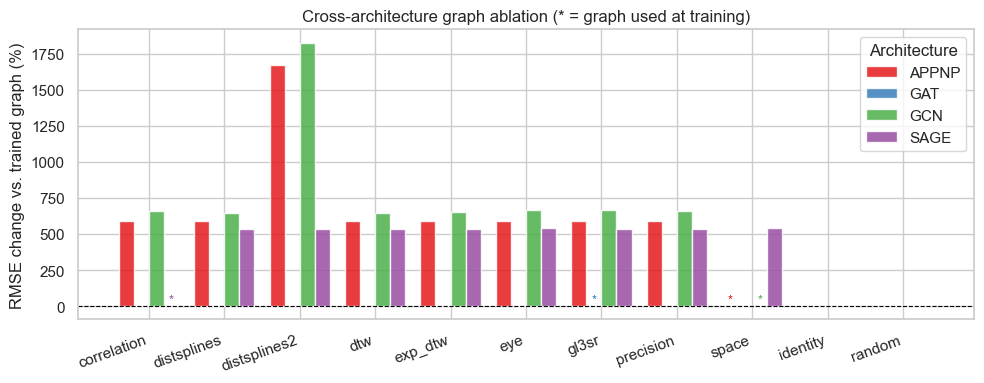

Saved: results_interpretability/cross_arch_graph_ablation.pdf


In [36]:
# ---- Cross-architecture graph ablation ----
# Trains GCN, SAGE, APPNP with best configs (rfrance) and runs the same
# topology swap as Section 11 for each model.
# Requires ds_train / ds_val / ds_test and model (GAT) already set up above.

import copy
import json as _json
import numpy as np
import pandas as pd
import torch
from torch_geometric import seed_everything
from torch_geometric.nn.conv import GCNConv, SAGEConv, APPNP
from torch_geometric.nn import GraphSAGE
from graphtoolbox.models.gnn import myGNN
from graphtoolbox.training.trainer import Trainer

OUT_CHANNELS = 48
NUM_EPOCHS = 10
_DEVICE = torch.device("mps" if torch.mps.is_available() else "cpu")

def _eval_with_trainer(trainer_obj, ds_variant):
    """Evaluate a pre-trained Trainer on a graph-variant dataset.

    Reuses trainer._predict() exactly as the paper pipeline does:
    - float32 cast before MPS move
    - _rescale_predictions (per-node inverse transform)
    - mask_Y applied to predictions
    - .sum(dim=0) for national aggregate
    The only difference from the standard test is the edge_index in ds_variant.
    """
    from torch_geometric.loader import DataLoader as PyGDataLoader
    loader = PyGDataLoader(ds_variant, batch_size=16, shuffle=False, drop_last=True)
    # temporarily swap dataset_test so _predict uses the right mask_Y
    original_ds_test = trainer_obj.dataset_test
    trainer_obj.dataset_test = ds_variant
    loss, pred_rescaled, y_targets = trainer_obj._predict(loader)
    trainer_obj.dataset_test = original_ds_test
    pred_agg = pred_rescaled.sum(dim=0).numpy().astype(float)
    tgt_agg  = y_targets.sum(dim=0).numpy().astype(float)
    valid = np.isfinite(pred_agg) & np.isfinite(tgt_agg)
    return regression_metrics(tgt_agg[valid], pred_agg[valid])


def run_ablation_for_model(trainer_obj, trained_adj, data_obj, ds_train_obj,
                           graph_folder_path, dataset_kwargs_base,
                           baseline_pred=None, baseline_target=None):
    """
    Evaluate a pre-trained Trainer on every graph matrix in graph_folder_path
    plus two degenerate baselines (identity, random).
    trained_adj: the adj_matrix name the model was trained with (used as reference).
    baseline_pred/target: [nodes, T] MW-scale tensors from trainer.train() —
        used directly for the trained-graph row to match paper numbers exactly.
    """
    import os
    import graphtoolbox.training.metrics as _metrics
    available = sorted(os.listdir(graph_folder_path))
    rows = []
    for adj_name in available:
        is_trained = adj_name == trained_adj
        # For the trained graph, reuse stored pred/target from trainer.train()
        if is_trained and baseline_pred is not None and baseline_target is not None:
            pred_agg = baseline_pred.sum(dim=0).cpu().numpy().astype(float)
            tgt_agg  = baseline_target.sum(dim=0).cpu().numpy().astype(float)
            valid = np.isfinite(pred_agg) & np.isfinite(tgt_agg)
            m = regression_metrics(tgt_agg[valid], pred_agg[valid])
            rows.append({"variant": adj_name, "rmse": m["rmse"], "mape": m["mape"],
                         "trained": True})
            continue
        dkw = dict(dataset_kwargs_base, adj_matrix=adj_name)
        try:
            ds_variant = GraphDataset(data=data_obj, period="test",
                                      scalers_feat=ds_train_obj.scalers_feat,
                                      scalers_target=ds_train_obj.scalers_target,
                                      graph_folder=graph_folder_path,
                                      dataset_kwargs=dkw,
                                      out_channels=OUT_CHANNELS)
        except Exception as e:
            rows.append({"variant": adj_name, "rmse": np.nan, "mape": np.nan,
                         "trained": is_trained, "error": str(e)[:60]})
            continue
        m = _eval_with_trainer(trainer_obj, ds_variant)
        rows.append({"variant": adj_name,
                     "rmse": m["rmse"], "mape": m["mape"],
                     "trained": is_trained})

    # Degenerate baselines: build a fake dataset with identity / random edge_index
    # by patching ds_variant in-place (restored after each eval)
    ds_last = ds_variant  # reuse last successfully loaded variant dataset
    for kind in ["identity", "random"]:
        try:
            # build the degenerate edge_index from one sample
            sample0 = ds_last[0]
            degen = build_graph_variant(sample0, kind, seed=42)
            degen_edge_index = degen.edge_index.cpu()
            # temporarily patch every sample's edge_index in the dataset
            # via _set_adj_matrix is not available for synthetic graphs,
            # so we monkey-patch the cached graph attribute
            original_edge_index = ds_last.data.edge_index.clone() if hasattr(ds_last, "_data") else None
            if original_edge_index is not None:
                ds_last.data.edge_index = degen_edge_index
                ds_last.data.edge_weight = None
                m = _eval_with_trainer(trainer_obj, ds_last)
                ds_last.data.edge_index = original_edge_index
            else:
                m = {"rmse": np.nan, "mape": np.nan}
        except Exception as e:
            m = {"rmse": np.nan, "mape": np.nan}
            print(f"  Degenerate baseline '{kind}' failed: {e}")
        rows.append({"variant": kind, "rmse": m["rmse"], "mape": m["mape"],
                     "trained": False})

    out = pd.DataFrame(rows)
    ref = out.loc[out["trained"] == True, "rmse"]
    base_rmse = float(ref.iloc[0]) if len(ref) else float(out["rmse"].min())
    out["delta_rmse_vs_trained"] = out["rmse"] - base_rmse
    out["delta_rmse_pct_vs_trained"] = 100.0 * out["delta_rmse_vs_trained"] / (base_rmse + 1e-12)
    return out


if "ds_train" in dir() and ds_train is not None:
    with open("configs/config_rfrance.json") as _f:
        cfg_all = _json.load(_f)

    # Base dataset_kwargs (features, target, node_var) without adj_matrix
    # Each architecture will override adj_matrix with its best trained graph.
    dataset_kwargs_base = {k: v for k, v in dataset_kwargs.items() if k != "adj_matrix"}

    gat_cfg = cfg_all["GATConv"]
    from torch_geometric.loader import DataLoader as _PyGDL
    _gat_loader = _PyGDL(ds_test, batch_size=16, shuffle=False, drop_last=True)
    _, gat_pred, gat_target = trainer._predict(_gat_loader)
    arch_specs = {"GAT": {"model": model, "trainer": trainer, "ds_test": ds_test,
                          "ds_train": ds_train, "trained_adj": gat_cfg["adj_matrix"],
                          "pred": gat_pred, "target": gat_target}}

    # ---- GCN ----
    gcn_cfg = cfg_all["GCNConv"]
    gcn_params = gcn_cfg["params"]
    gcn_adj = gcn_cfg["adj_matrix"]
    dkw_gcn = dict(dataset_kwargs, adj_matrix=gcn_adj)
    ds_train_gcn = GraphDataset(data=data, period="train", graph_folder=graph_folder,
                                dataset_kwargs=dkw_gcn, out_channels=OUT_CHANNELS)
    ds_val_gcn   = GraphDataset(data=data, period="val",
                                scalers_feat=ds_train_gcn.scalers_feat,
                                scalers_target=ds_train_gcn.scalers_target,
                                graph_folder=graph_folder, dataset_kwargs=dkw_gcn,
                                out_channels=OUT_CHANNELS)
    ds_test_gcn  = GraphDataset(data=data, period="test",
                                scalers_feat=ds_train_gcn.scalers_feat,
                                scalers_target=ds_train_gcn.scalers_target,
                                graph_folder=graph_folder, dataset_kwargs=dkw_gcn,
                                out_channels=OUT_CHANNELS)
    seed_everything(42)
    gcn_model = myGNN(in_channels=ds_train_gcn.num_node_features,
                      num_layers=gcn_params["num_layers"],
                      hidden_channels=gcn_params["hidden_channels"],
                      out_channels=OUT_CHANNELS, conv_class=GCNConv,
                      conv_kwargs={}).to(_DEVICE)
    gcn_trainer = Trainer(model=gcn_model, dataset_train=ds_train_gcn, dataset_val=ds_val_gcn,
            dataset_test=ds_test_gcn, batch_size=gcn_params["batch_size"],
            return_attention=False,
            model_kwargs={"lr": gcn_params["lr"], "num_epochs": NUM_EPOCHS},
            lam_reg=0)
    pred_model_test, target_test, _, _ = gcn_trainer.train(plot_loss=False, force_training=True, save=False, patience=100)
    print("GCN trained.")
    arch_specs["GCN"] = {"model": gcn_model, "ds_test": ds_test_gcn, "ds_train": ds_train_gcn, "trained_adj": gcn_adj, "pred": pred_model_test, "target": target_test, "trainer": gcn_trainer}

    # ---- GraphSAGE ----
    sage_cfg = cfg_all["GraphSAGE"]
    sage_params = sage_cfg["params"]
    sage_adj = sage_cfg["adj_matrix"]
    dkw_sage = dict(dataset_kwargs, adj_matrix=sage_adj)
    ds_train_sage = GraphDataset(data=data, period="train", graph_folder=graph_folder,
                                 dataset_kwargs=dkw_sage, out_channels=OUT_CHANNELS)
    ds_val_sage   = GraphDataset(data=data, period="val",
                                 scalers_feat=ds_train_sage.scalers_feat,
                                 scalers_target=ds_train_sage.scalers_target,
                                 graph_folder=graph_folder, dataset_kwargs=dkw_sage,
                                 out_channels=OUT_CHANNELS)
    ds_test_sage  = GraphDataset(data=data, period="test",
                                 scalers_feat=ds_train_sage.scalers_feat,
                                 scalers_target=ds_train_sage.scalers_target,
                                 graph_folder=graph_folder, dataset_kwargs=dkw_sage,
                                 out_channels=OUT_CHANNELS)
    seed_everything(42)
    sage_model = myGNN(in_channels=ds_train_sage.num_node_features,
                      num_layers=sage_params["num_layers"],
                      hidden_channels=sage_params["hidden_channels"],
                      out_channels=OUT_CHANNELS, conv_class=SAGEConv,
                      conv_kwargs={}).to(_DEVICE)
    sage_trainer = Trainer(model=sage_model, dataset_train=ds_train_sage, dataset_val=ds_val_sage,
            dataset_test=ds_test_sage, batch_size=sage_params["batch_size"],
            return_attention=False,
            model_kwargs={"lr": sage_params["lr"], "num_epochs": NUM_EPOCHS},
            lam_reg=0)
    pred_model_test, target_test, _, _ = sage_trainer.train(plot_loss=False, force_training=True, save=False, patience=100)
    print("GraphSAGE trained.")
    arch_specs["SAGE"] = {"model": sage_model, "ds_test": ds_test_sage, "ds_train": ds_train_sage, "trained_adj": sage_adj, "pred": pred_model_test, "target": target_test, "trainer": sage_trainer}

    # ---- APPNP ----
    appnp_cfg = cfg_all["APPNP"]
    appnp_params = appnp_cfg["params"]
    appnp_adj = appnp_cfg["adj_matrix"]
    dkw_appnp = dict(dataset_kwargs, adj_matrix=appnp_adj)
    ds_train_appnp = GraphDataset(data=data, period="train", graph_folder=graph_folder,
                                  dataset_kwargs=dkw_appnp, out_channels=OUT_CHANNELS)
    ds_val_appnp   = GraphDataset(data=data, period="val",
                                  scalers_feat=ds_train_appnp.scalers_feat,
                                  scalers_target=ds_train_appnp.scalers_target,
                                  graph_folder=graph_folder, dataset_kwargs=dkw_appnp,
                                  out_channels=OUT_CHANNELS)
    ds_test_appnp  = GraphDataset(data=data, period="test",
                                  scalers_feat=ds_train_appnp.scalers_feat,
                                  scalers_target=ds_train_appnp.scalers_target,
                                  graph_folder=graph_folder, dataset_kwargs=dkw_appnp,
                                  out_channels=OUT_CHANNELS)
    seed_everything(42)
    appnp_model = myGNN(in_channels=ds_train_appnp.num_node_features,
                        num_layers=appnp_params["num_layers"],
                        hidden_channels=appnp_params["hidden_channels"],
                        out_channels=OUT_CHANNELS, conv_class=APPNP,
                        conv_kwargs={"K": appnp_params.get("K", 10),
                                     "alpha": appnp_params.get("alpha", 0.1)}).to(_DEVICE)
    appnp_trainer = Trainer(model=appnp_model, dataset_train=ds_train_appnp, dataset_val=ds_val_appnp,
            dataset_test=ds_test_appnp, batch_size=appnp_params["batch_size"],
            return_attention=False,
            model_kwargs={"lr": appnp_params["lr"], "num_epochs": NUM_EPOCHS},
            lam_reg=0)
    pred_model_test, target_test, _, _ = appnp_trainer.train(plot_loss=False, force_training=True, save=False, patience=100)
    print("APPNP trained.")
    arch_specs["APPNP"] = {"model": appnp_model, "ds_test": ds_test_appnp, "ds_train": ds_train_appnp, "trained_adj": appnp_adj, "pred": pred_model_test, "target": target_test, "trainer": appnp_trainer}

    # ---- Run ablation ----
    all_ablation = []
    for arch_name, spec in arch_specs.items():
        print(f"Running graph ablation for {arch_name}...")
        spec["model"].eval()
        abl = run_ablation_for_model(
            trainer_obj=spec["trainer"],
            trained_adj=spec["trained_adj"],
            data_obj=data,
            ds_train_obj=spec["ds_train"],
            graph_folder_path=graph_folder,
            dataset_kwargs_base=dataset_kwargs_base,
            baseline_pred=spec.get("pred"),
            baseline_target=spec.get("target"),
        )
        abl.insert(0, "arch", arch_name)
        all_ablation.append(abl)
        print(f"  done ({arch_name})")

    df_cross_ablation = pd.concat(all_ablation, ignore_index=True)

    # ---- Summary pivot: RMSE delta vs. each architecture's own trained graph ----
    pivot = df_cross_ablation.pivot(index="variant", columns="arch",
                                    values="delta_rmse_pct_vs_trained")
    # Row order: trained graph first (alphabetical for real graphs), then degenerate
    real_variants = sorted([v for v in pivot.index if v not in ("identity", "random")])
    row_order = real_variants + [v for v in ("identity", "random") if v in pivot.index]
    pivot = pivot.reindex(row_order)
    print()
    print("Graph ablation: RMSE change (%) vs. each model's own trained graph")
    print("0 = trained graph  |  Positive = worse  |  Negative = better")
    print()
    display(pivot.round(2))

    # Mark which graph each architecture was trained on
    trained_map = {spec_name: spec["trained_adj"]
                   for spec_name, spec in arch_specs.items()}
    print("Trained graphs:", trained_map)

    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(10, 4))
    arch_names = list(pivot.columns)
    x = np.arange(len(pivot))
    width = 0.2
    colors = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3"]
    for i, (arch, color) in enumerate(zip(arch_names, colors)):
        vals = pivot[arch].fillna(0).values
        bars = ax.bar(x + i * width, vals, width, label=arch, color=color, alpha=0.85)
        # Mark the variant this arch was trained on
        trained_adj = trained_map.get(arch, "")
        for j, variant in enumerate(pivot.index):
            if variant == trained_adj:
                ax.annotate("*", (x[j] + i * width, vals[j]),
                            ha="center", va="bottom", fontsize=9, color=color)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks(x + width * (len(arch_names) - 1) / 2)
    ax.set_xticklabels(pivot.index, rotation=20, ha="right")
    ax.set_ylabel("RMSE change vs. trained graph (%)")
    ax.set_title("Cross-architecture graph ablation (* = graph used at training)")
    ax.legend(title="Architecture")
    plt.tight_layout()
    plt.savefig("results_interpretability/cross_arch_graph_ablation.pdf",
                bbox_inches="tight")
    plt.show()
    print("Saved: results_interpretability/cross_arch_graph_ablation.pdf")

else:
    print("ds_train not found. Run cell 9 (Section 8) first to set up datasets.")


In [61]:
df_cross_ablation

,arch,variant,rmse,mape,trained,delta_rmse_vs_trained,delta_rmse_pct_vs_trained
0,GAT,correlation,11457.127498,0.176820,False,-0.000050,-4.325594e-07
1,GAT,distsplines,11457.127513,0.176820,False,-0.000035,-3.018089e-07
2,GAT,distsplines2,11457.127532,0.176820,False,-0.000016,-1.410187e-07
3,GAT,dtw,11442.541475,0.176686,False,-14.586072,-1.273100e-01
4,GAT,exp_dtw,11545.412681,0.176827,False,88.285133,7.705695e-01
5,GAT,eye,11561.724241,0.176724,False,104.596693,9.129399e-01
6,GAT,gl3sr,11457.127548,0.176820,True,0.000000,0.000000e+00
7,GAT,precision,11457.127490,0.176820,False,-0.000058,-5.039810e-07
8,GAT,space,11446.175815,0.177073,False,-10.951733,-9.558882e-02
9,GAT,identity,NaN,NaN,False,NaN,NaN
